In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/diabetic_data.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [2]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Columns:")
print(df.columns.tolist())

Dataset Shape: (101766, 50)

First 5 Records:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Dataset Columns:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nDataset Information:")
df.info()


Number of Rows: 101766
Number of Columns: 50

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures    

In [4]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing_summary.head(20))

,Missing_Count,Missing_Percentage
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
race,0,0.00
gender,0,0.00
age,0,0.00
weight,0,0.00
admission_type_id,0,0.00
discharge_disposition_id,0,0.00
admission_source_id,0,0.00
time_in_hospital,0,0.00


In [5]:
question_marks = (df == "?").sum()

question_summary = pd.DataFrame({
    "Question_Mark_Count": question_marks,
    "Percentage": (
        question_marks / len(df) * 100
    ).round(2)
})

question_summary = question_summary[
    question_summary["Question_Mark_Count"] > 0
].sort_values(
    by="Question_Mark_Count",
    ascending=False
)

display(question_summary)

,Question_Mark_Count,Percentage
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [6]:
print("Readmission Categories:")
print(df["readmitted"].value_counts())

print("\nGender Categories:")
print(df["gender"].value_counts())

print("\nAge Groups:")
print(df["age"].value_counts().sort_index())

Readmission Categories:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Gender Categories:
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

Age Groups:
age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64


In [7]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

print("Total Unique Encounters:", df["encounter_id"].nunique())

print("Total Unique Patients:", df["patient_nbr"].nunique())

Total Duplicate Rows: 0
Total Unique Encounters: 101766
Total Unique Patients: 71518


In [8]:
# Statistical Summary of Numerical Columns

display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


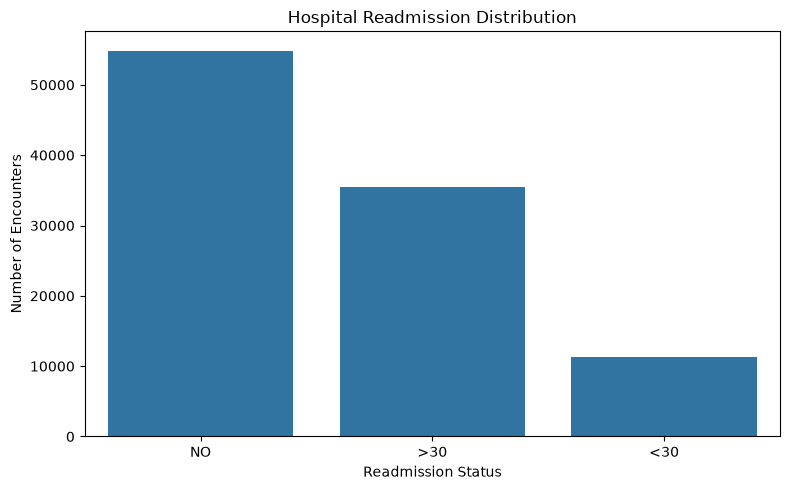

In [9]:
# Readmission Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="readmitted",
    order=["NO", ">30", "<30"]
)

plt.title("Hospital Readmission Distribution")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Encounters")

plt.tight_layout()
plt.show()

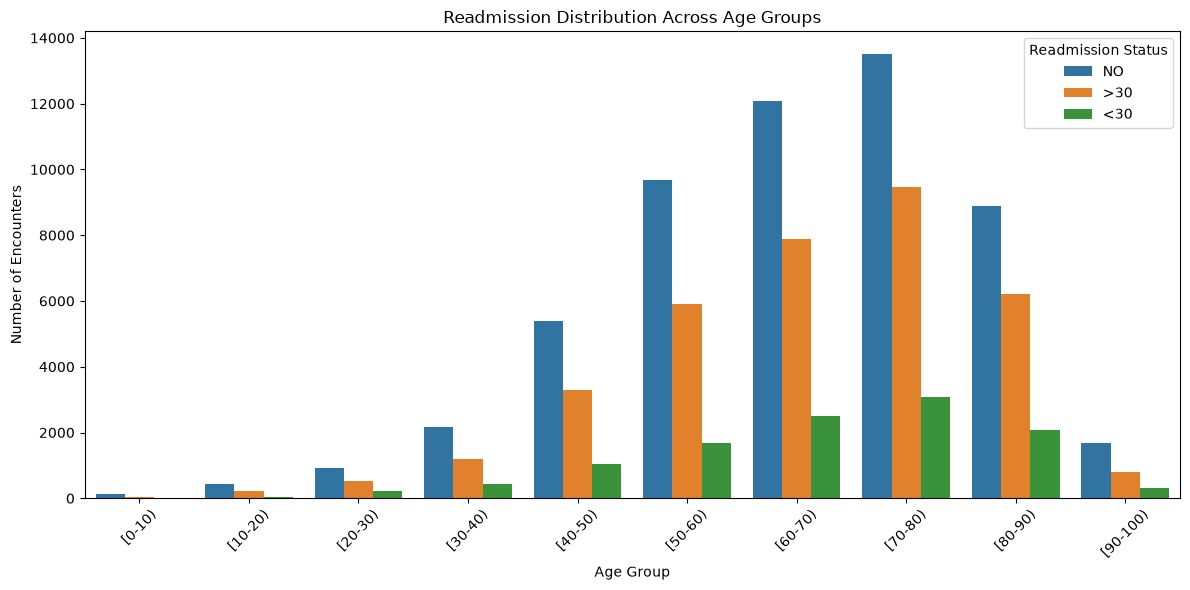

In [10]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="age",
    hue="readmitted",
    order=[
        "[0-10)", "[10-20)", "[20-30)",
        "[30-40)", "[40-50)", "[50-60)",
        "[60-70)", "[70-80)", "[80-90)",
        "[90-100)"
    ]
)

plt.title("Readmission Distribution Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=45)
plt.legend(title="Readmission Status")

plt.tight_layout()
plt.show()

In [11]:
age_readmission = pd.crosstab(
    df["age"],
    df["readmitted"],
    normalize="index"
) * 100

display(age_readmission.round(2))

readmitted,<30,>30,NO
age,,,
[0-10),1.86,16.15,81.99
[10-20),5.79,32.42,61.79
[20-30),14.24,30.78,54.98
[30-40),11.23,31.44,57.32
[40-50),10.60,33.85,55.55
[50-60),9.67,34.29,56.04
[60-70),11.13,35.12,53.75
[70-80),11.77,36.35,51.88
[80-90),12.08,36.19,51.73


In [12]:
gender_readmission = pd.crosstab(
    df["gender"],
    df["readmitted"],
    normalize="index"
) * 100

display(gender_readmission.round(2))

readmitted,<30,>30,NO
gender,,,
Female,11.25,35.68,53.08
Male,11.06,34.06,54.88
Unknown/Invalid,0.00,0.00,100.00


In [13]:
stay_readmission = df.groupby(
    "readmitted"
)["time_in_hospital"].agg(
    ["count", "mean", "median"]
)

display(stay_readmission.round(2))


,count,mean,median
readmitted,,,
<30,11357,4.77,4.0
>30,35545,4.50,4.0
NO,54864,4.25,3.0


In [14]:
previous_visits = df.groupby(
    "readmitted"
)[
    [
        "number_outpatient",
        "number_emergency",
        "number_inpatient"
    ]
].mean()

display(previous_visits.round(2))

,number_outpatient,number_emergency,number_inpatient
readmitted,,,
<30,0.44,0.36,1.22
>30,0.50,0.28,0.84
NO,0.27,0.11,0.38


In [15]:
medical_activity = df.groupby("readmitted")[
    [
        "num_lab_procedures",
        "num_procedures",
        "num_medications",
        "number_diagnoses"
    ]
].mean()

display(medical_activity.round(2))

,num_lab_procedures,num_procedures,num_medications,number_diagnoses
readmitted,,,,
<30,44.23,1.28,16.90,7.69
>30,43.84,1.25,16.28,7.65
NO,42.38,1.41,15.67,7.22


In [16]:
medication_readmission = pd.crosstab(
    df["diabetesMed"],
    df["readmitted"],
    normalize="index"
) * 100

display(medication_readmission.round(2))

readmitted,<30,>30,NO
diabetesMed,,,
No,9.60,30.88,59.52
Yes,11.63,36.14,52.24


In [17]:
medication_change = pd.crosstab(
    df["change"],
    df["readmitted"],
    normalize="index"
) * 100

display(medication_change.round(2))


readmitted,<30,>30,NO
change,,,
Ch,11.82,36.74,51.44
No,10.59,33.37,56.04


In [18]:
print(df["admission_type_id"].value_counts().sort_index())

admission_type_id
1    53990
2    18480
3    18869
4       10
5     4785
6     5291
7       21
8      320
Name: count, dtype: int64


In [19]:
admission_mapping = {
    1: "Emergency",
    2: "Urgent",
    3: "Elective",
    4: "Newborn",
    5: "Not Available",
    6: "NULL",
    7: "Trauma Center",
    8: "Not Mapped"
}

df["admission_type"] = df["admission_type_id"].map(
    admission_mapping
)

print(df["admission_type"].value_counts())

admission_type
Emergency        53990
Elective         18869
Urgent           18480
NULL              5291
Not Available     4785
Not Mapped         320
Trauma Center       21
Newborn             10
Name: count, dtype: int64


In [20]:
admission_readmission = pd.crosstab(
    df["admission_type"],
    df["readmitted"],
    normalize="index"
) * 100

display(admission_readmission.round(2))


readmitted,<30,>30,NO
admission_type,,,
Elective,10.39,30.45,59.16
Emergency,11.52,35.76,52.71
NULL,11.08,42.17,46.76
Newborn,10.00,20.00,70.00
Not Available,10.34,35.97,53.69
Not Mapped,8.44,26.25,65.31
Trauma Center,0.00,0.00,100.00
Urgent,11.18,34.91,53.91


In [ ]:
print(
    df["discharge_disposition_id"]
    .value_counts()
    .sort_index()
)

In [23]:
discharge_mapping = {
    1: "Discharged to Home",
    2: "Expired",
    3: "Transferred to Short-Term Hospital",
    4: "Transferred to Skilled Nursing Facility",
    5: "Transferred to Intermediate Care Facility",
    6: "Other Inpatient Care Institution",
    7: "Left Against Medical Advice",
    8: "Home with Home IV Provider",
    9: "Admitted to Same Hospital",
    10: "Neonate Transferred to Another Hospital",
    11: "Expired",
    12: "Still Patient / Outpatient Return",
    13: "Hospice at Home",
    14: "Hospice at Medical Facility",
    15: "Other Institution Outpatient Transfer",
    16: "Same Institution Outpatient Transfer",
    17: "Medicare Swing Bed",
    18: "NULL",
    19: "Expired at Home",
    20: "Expired in Medical Facility",
    22: "Rehabilitation Facility",
    23: "Long-Term Care Hospital",
    24: "Medicaid Nursing Facility",
    25: "Not Mapped",
    27: "Federal Healthcare Facility",
    28: "Psychiatric Hospital"
}

df["discharge_category"] = df[
    "discharge_disposition_id"
].map(discharge_mapping)

print(df["discharge_category"].value_counts())

discharge_category
Discharged to Home                           60234
Transferred to Short-Term Hospital           13954
Other Inpatient Care Institution             12902
Expired                                       3770
NULL                                          3691
Rehabilitation Facility                       1993
Transferred to Intermediate Care Facility     1184
Not Mapped                                     989
Transferred to Skilled Nursing Facility        815
Left Against Medical Advice                    623
Long-Term Care Hospital                        412
Hospice at Home                                399
Hospice at Medical Facility                    372
Psychiatric Hospital                           139
Home with Home IV Provider                     108
Other Institution Outpatient Transfer           63
Medicaid Nursing Facility                       48
Admitted to Same Hospital                       21
Medicare Swing Bed                              14
Same Institu

In [24]:
discharge_readmission = pd.crosstab(
    df["discharge_category"],
    df["readmitted"],
    normalize="index"
) * 100

display(
    discharge_readmission.round(2).sort_values(
        by="<30",
        ascending=False
    )
)

readmitted,<30,>30,NO
discharge_category,,,
Still Patient / Outpatient Return,66.67,0.00,33.33
Other Institution Outpatient Transfer,44.44,28.57,26.98
Admitted to Same Hospital,42.86,9.52,47.62
Psychiatric Hospital,36.69,24.46,38.85
Rehabilitation Facility,27.70,26.04,46.26
Transferred to Intermediate Care Facility,20.86,29.56,49.58
Transferred to Short-Term Hospital,14.66,35.23,50.11
Medicaid Nursing Facility,14.58,33.33,52.08
Left Against Medical Advice,14.45,35.47,50.08


In [25]:
print(
    df["admission_source_id"]
    .value_counts()
    .sort_index()
)

admission_source_id
1     29565
2      1104
3       187
4      3187
5       855
6      2264
7     57494
8        16
9       125
10        8
11        2
13        1
14        2
17     6781
20      161
22       12
25        2
Name: count, dtype: int64


In [26]:
admission_source_mapping = {
    1: "Physician Referral",
    2: "Clinic Referral",
    3: "HMO Referral",
    4: "Transfer from Hospital",
    5: "Transfer from Skilled Nursing Facility",
    6: "Transfer from Healthcare Facility",
    7: "Emergency Room",
    8: "Court / Law Enforcement",
    9: "Not Available",
    10: "Transfer from Critical Access Hospital",
    11: "Normal Delivery",
    13: "Sick Baby",
    14: "Extramural Birth",
    17: "NULL",
    20: "Not Mapped",
    22: "Transfer from Same Hospital",
    25: "Transfer from Ambulatory Surgery Center"
}

df["admission_source"] = df[
    "admission_source_id"
].map(admission_source_mapping)

print(df["admission_source"].value_counts())

admission_source
Emergency Room                             57494
Physician Referral                         29565
NULL                                        6781
Transfer from Hospital                      3187
Transfer from Healthcare Facility           2264
Clinic Referral                             1104
Transfer from Skilled Nursing Facility       855
HMO Referral                                 187
Not Mapped                                   161
Not Available                                125
Court / Law Enforcement                       16
Transfer from Same Hospital                   12
Transfer from Critical Access Hospital         8
Extramural Birth                               2
Normal Delivery                                2
Transfer from Ambulatory Surgery Center        2
Sick Baby                                      1
Name: count, dtype: int64


In [27]:
admission_readmission = pd.crosstab(
    df["admission_source"],
    df["readmitted"],
    normalize="index"
) * 100

display(admission_readmission.round(2))

readmitted,<30,>30,NO
admission_source,,,
Clinic Referral,10.05,28.08,61.87
Court / Law Enforcement,12.50,25.00,62.50
Emergency Room,11.69,37.69,50.63
Extramural Birth,0.00,0.00,100.00
HMO Referral,15.51,31.02,53.48
NULL,10.41,36.25,53.34
Normal Delivery,0.00,0.00,100.00
Not Available,10.40,12.80,76.80
Not Mapped,13.66,50.31,36.02


In [28]:
admission_source_counts = (
    df["admission_source"]
    .value_counts()
    .rename("Patient_Count")
)

display(admission_source_counts.to_frame())

,Patient_Count
admission_source,
Emergency Room,57494
Physician Referral,29565
NULL,6781
Transfer from Hospital,3187
Transfer from Healthcare Facility,2264
Clinic Referral,1104
Transfer from Skilled Nursing Facility,855
HMO Referral,187
Not Mapped,161


In [ ]:
plt.figure(figsize=(12, 7))

admission_source_counts.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Patient Count by Admission Source")
plt.xlabel("Number of Patients")
plt.ylabel("Admission Source")
plt.tight_layout()
plt.show()

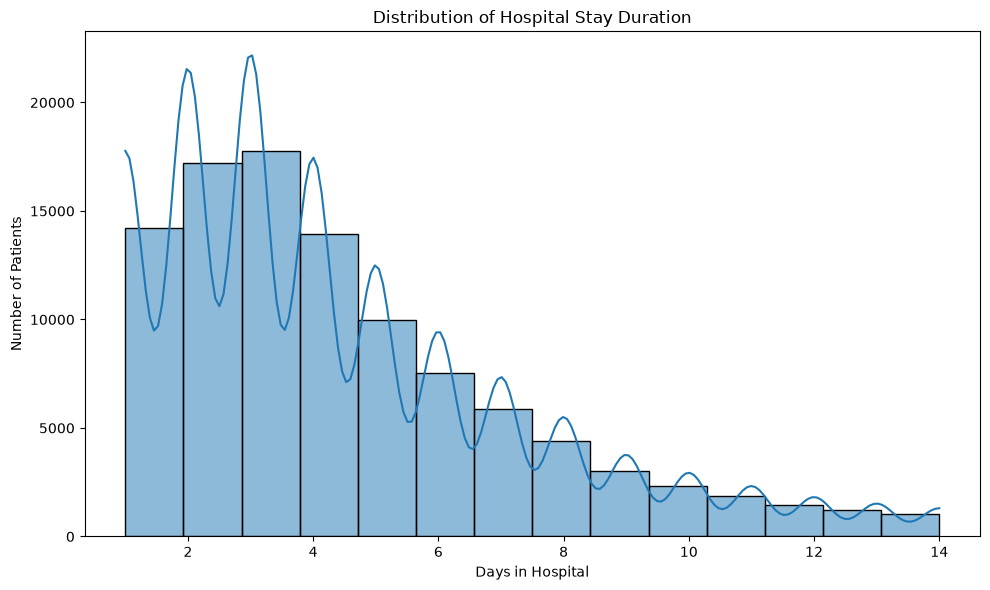

In [30]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["time_in_hospital"],
    bins=14,
    kde=True
)

plt.title("Distribution of Hospital Stay Duration")
plt.xlabel("Days in Hospital")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()


In [31]:
df["time_in_hospital"].value_counts().sort_index()

time_in_hospital
1     14208
2     17224
3     17756
4     13924
5      9966
6      7539
7      5859
8      4391
9      3002
10     2342
11     1855
12     1448
13     1210
14     1042
Name: count, dtype: int64

In [32]:
stay_readmission = df.groupby("readmitted")["time_in_hospital"].agg(
    ["count", "mean", "median"]
)

display(stay_readmission.round(2))

,count,mean,median
readmitted,,,
<30,11357,4.77,4.0
>30,35545,4.50,4.0
NO,54864,4.25,3.0


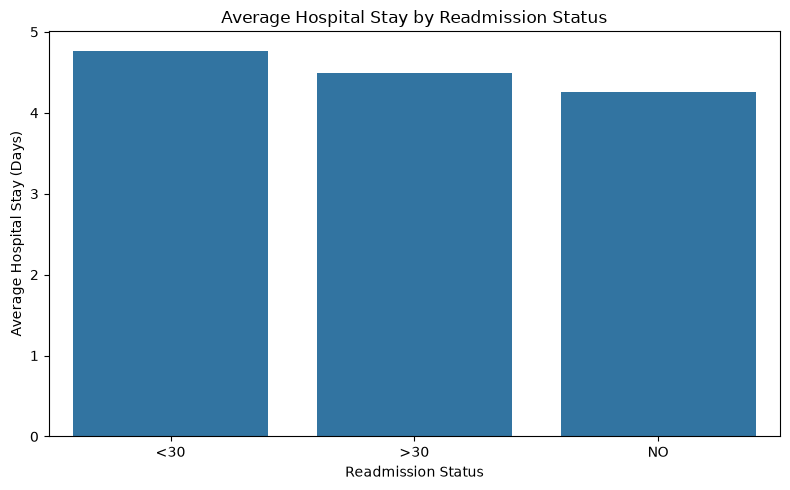

In [33]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=stay_readmission.index,
    y=stay_readmission["mean"]
)

plt.title("Average Hospital Stay by Readmission Status")
plt.xlabel("Readmission Status")
plt.ylabel("Average Hospital Stay (Days)")

plt.tight_layout()
plt.show()

In [34]:
previous_visits = df.groupby("readmitted")[
    ["number_outpatient", "number_emergency", "number_inpatient"]
].mean()

display(previous_visits.round(2))

,number_outpatient,number_emergency,number_inpatient
readmitted,,,
<30,0.44,0.36,1.22
>30,0.50,0.28,0.84
NO,0.27,0.11,0.38


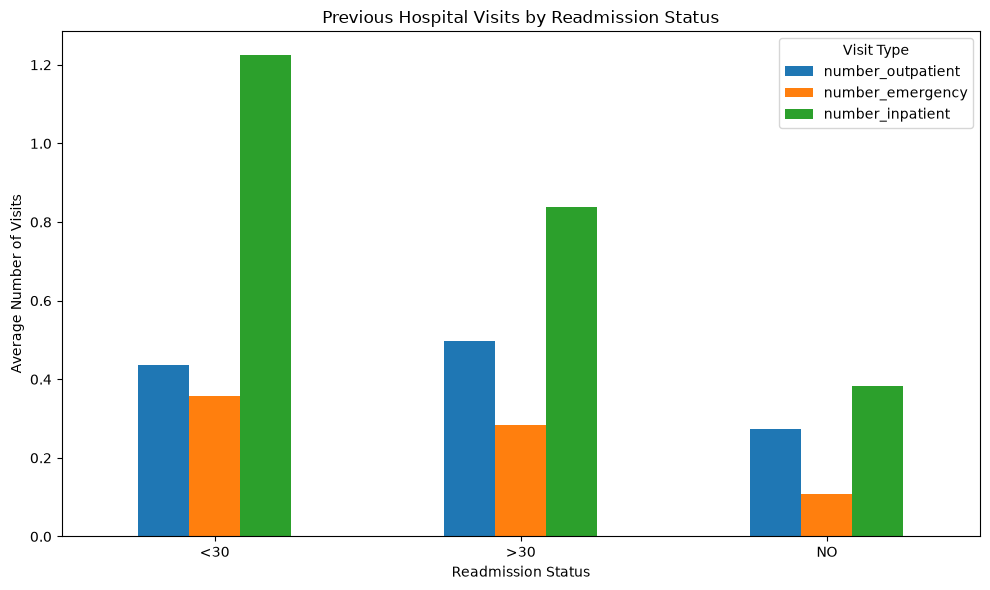

In [35]:
previous_visits.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Previous Hospital Visits by Readmission Status")
plt.xlabel("Readmission Status")
plt.ylabel("Average Number of Visits")
plt.xticks(rotation=0)
plt.legend(title="Visit Type")
plt.tight_layout()
plt.show()

In [36]:
medical_activity = df.groupby("readmitted")[
    [
        "num_lab_procedures",
        "num_procedures",
        "num_medications",
        "number_diagnoses"
    ]
].mean()

display(medical_activity.round(2))

,num_lab_procedures,num_procedures,num_medications,number_diagnoses
readmitted,,,,
<30,44.23,1.28,16.90,7.69
>30,43.84,1.25,16.28,7.65
NO,42.38,1.41,15.67,7.22


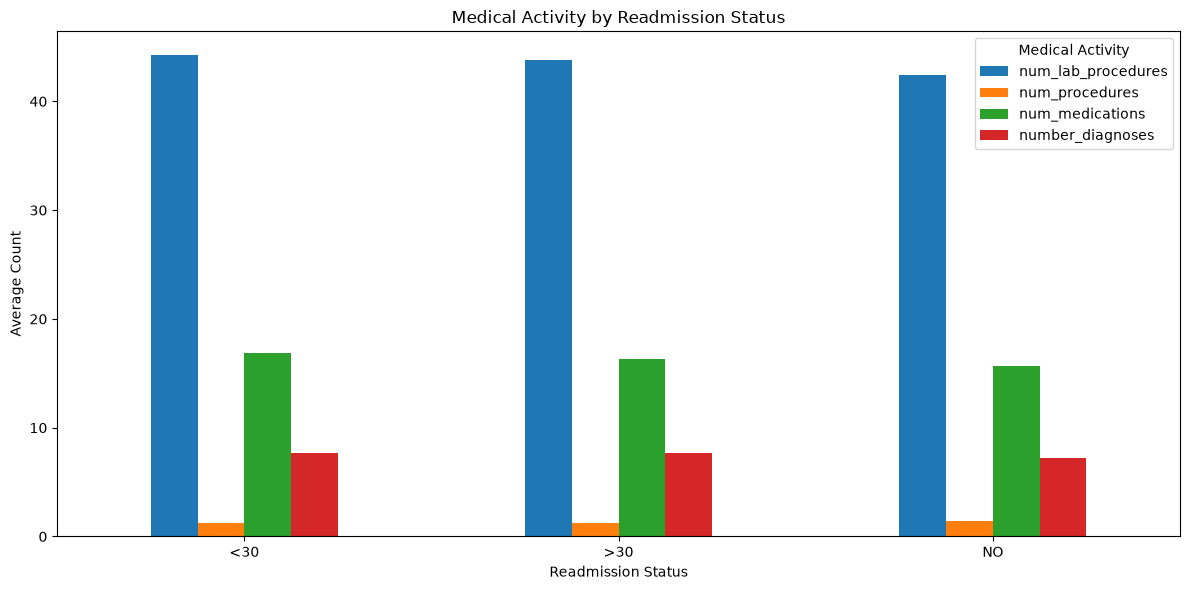

In [37]:
medical_activity.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Medical Activity by Readmission Status")
plt.xlabel("Readmission Status")
plt.ylabel("Average Count")
plt.xticks(rotation=0)
plt.legend(title="Medical Activity")
plt.tight_layout()
plt.show()

In [38]:
diabetes_med_readmission = pd.crosstab(
    df["diabetesMed"],
    df["readmitted"],
    normalize="index"
) * 100

display(diabetes_med_readmission.round(2))

readmitted,<30,>30,NO
diabetesMed,,,
No,9.60,30.88,59.52
Yes,11.63,36.14,52.24


In [39]:
medication_change = pd.crosstab(
    df["change"],
    df["readmitted"],
    normalize="index"
) * 100

display(medication_change.round(2))

readmitted,<30,>30,NO
change,,,
Ch,11.82,36.74,51.44
No,10.59,33.37,56.04


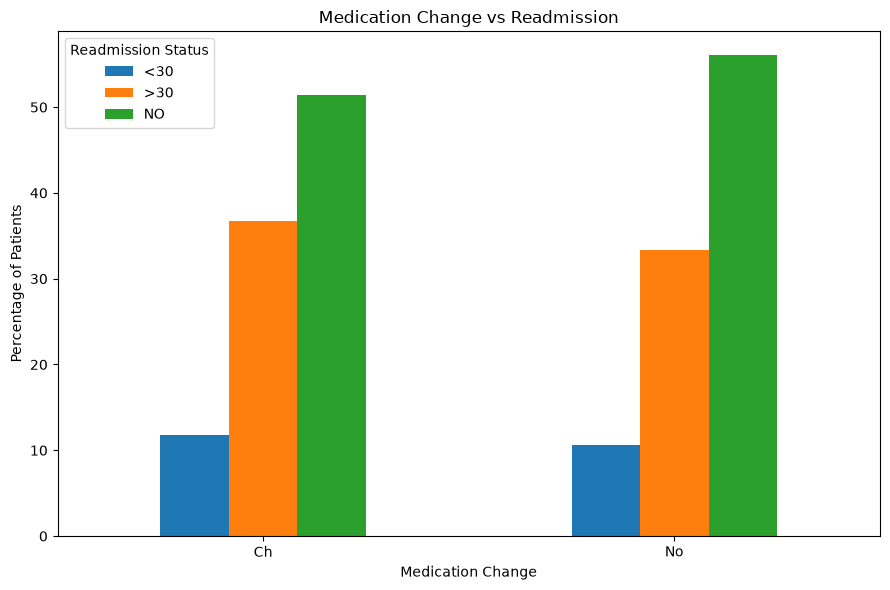

In [40]:
medication_change.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Medication Change vs Readmission")
plt.xlabel("Medication Change")
plt.ylabel("Percentage of Patients")
plt.xticks(rotation=0)
plt.legend(title="Readmission Status")
plt.tight_layout()
plt.show()

In [41]:
admission_type_readmission = pd.crosstab(
    df["admission_type"],
    df["readmitted"],
    normalize="index"
) * 100

display(admission_type_readmission.round(2))

readmitted,<30,>30,NO
admission_type,,,
Elective,10.39,30.45,59.16
Emergency,11.52,35.76,52.71
NULL,11.08,42.17,46.76
Newborn,10.00,20.00,70.00
Not Available,10.34,35.97,53.69
Not Mapped,8.44,26.25,65.31
Trauma Center,0.00,0.00,100.00
Urgent,11.18,34.91,53.91


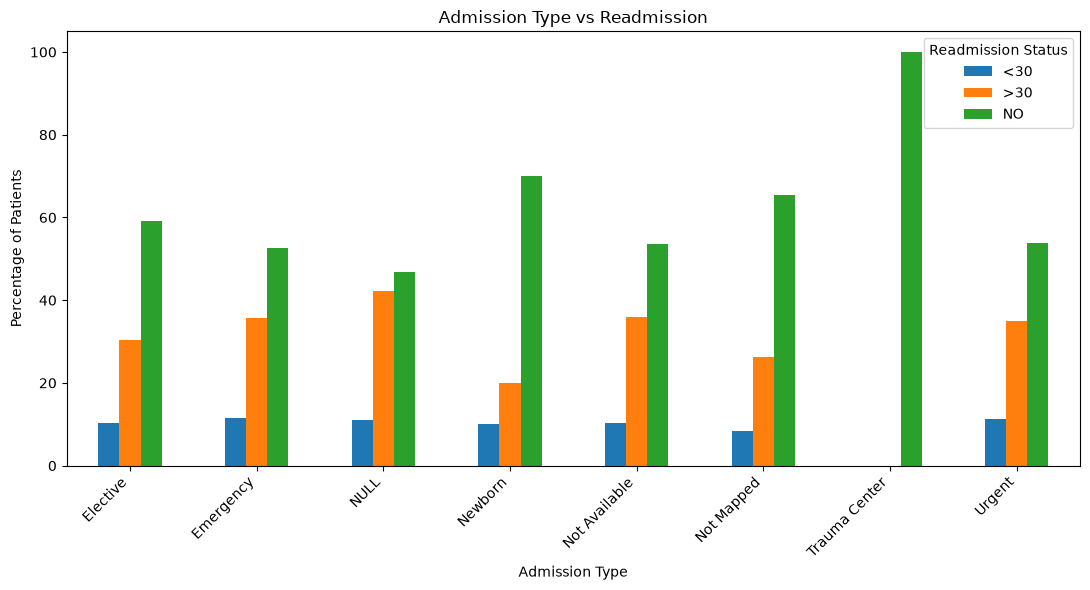

In [42]:
admission_type_readmission.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Admission Type vs Readmission")
plt.xlabel("Admission Type")
plt.ylabel("Percentage of Patients")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Readmission Status")
plt.tight_layout()
plt.show()

In [43]:
discharge_mapping = {
    1: "Discharged to Home",
    2: "Transferred to Short-Term Hospital",
    3: "Transferred to Skilled Nursing Facility",
    4: "Transferred to Intermediate Care Facility",
    5: "Other Inpatient Care Institution",
    6: "Home with Home Health Service",
    7: "Left Against Medical Advice",
    8: "Home with Home IV Provider",
    9: "Admitted to Same Hospital",
    10: "Neonate Transferred to Another Hospital",
    11: "Expired",
    12: "Still Patient / Outpatient Return",
    13: "Hospice at Home",
    14: "Hospice at Medical Facility",
    15: "Medicare Swing Bed",
    16: "Other Institution Outpatient Transfer",
    17: "Same Institution Outpatient Transfer",
    18: "NULL",
    19: "Expired at Home",
    20: "Expired in Medical Facility",
    22: "Rehabilitation Facility",
    23: "Long-Term Care Hospital",
    24: "Medicaid Nursing Facility",
    25: "Not Mapped",
    27: "Federal Healthcare Facility",
    28: "Psychiatric Hospital"
}

df["discharge_category"] = df["discharge_disposition_id"].map(
    discharge_mapping
)

print(df["discharge_category"].value_counts())

discharge_category
Discharged to Home                           60234
Transferred to Skilled Nursing Facility      13954
Home with Home Health Service                12902
NULL                                          3691
Transferred to Short-Term Hospital            2128
Rehabilitation Facility                       1993
Expired                                       1642
Other Inpatient Care Institution              1184
Not Mapped                                     989
Transferred to Intermediate Care Facility      815
Left Against Medical Advice                    623
Long-Term Care Hospital                        412
Hospice at Home                                399
Hospice at Medical Facility                    372
Psychiatric Hospital                           139
Home with Home IV Provider                     108
Medicare Swing Bed                              63
Medicaid Nursing Facility                       48
Admitted to Same Hospital                       21
Same Institu

In [44]:
discharge_readmission = pd.crosstab(
    df["discharge_category"],
    df["readmitted"],
    normalize="index"
) * 100

display(discharge_readmission.round(2))

readmitted,<30,>30,NO
discharge_category,,,
Admitted to Same Hospital,42.86,9.52,47.62
Discharged to Home,9.30,35.72,54.98
Expired,0.00,0.00,100.00
Expired at Home,0.00,0.00,100.00
Expired in Medical Facility,0.00,0.00,100.00
Federal Healthcare Facility,0.00,20.00,80.00
Home with Home Health Service,12.70,41.56,45.74
Home with Home IV Provider,13.89,35.19,50.93
Hospice at Home,4.76,9.02,86.22


In [45]:
discharge_counts = (
    df["discharge_category"]
    .value_counts()
    .rename("Patient_Count")
)

display(discharge_counts.to_frame())

,Patient_Count
discharge_category,
Discharged to Home,60234
Transferred to Skilled Nursing Facility,13954
Home with Home Health Service,12902
NULL,3691
Transferred to Short-Term Hospital,2128
Rehabilitation Facility,1993
Expired,1642
Other Inpatient Care Institution,1184
Not Mapped,989


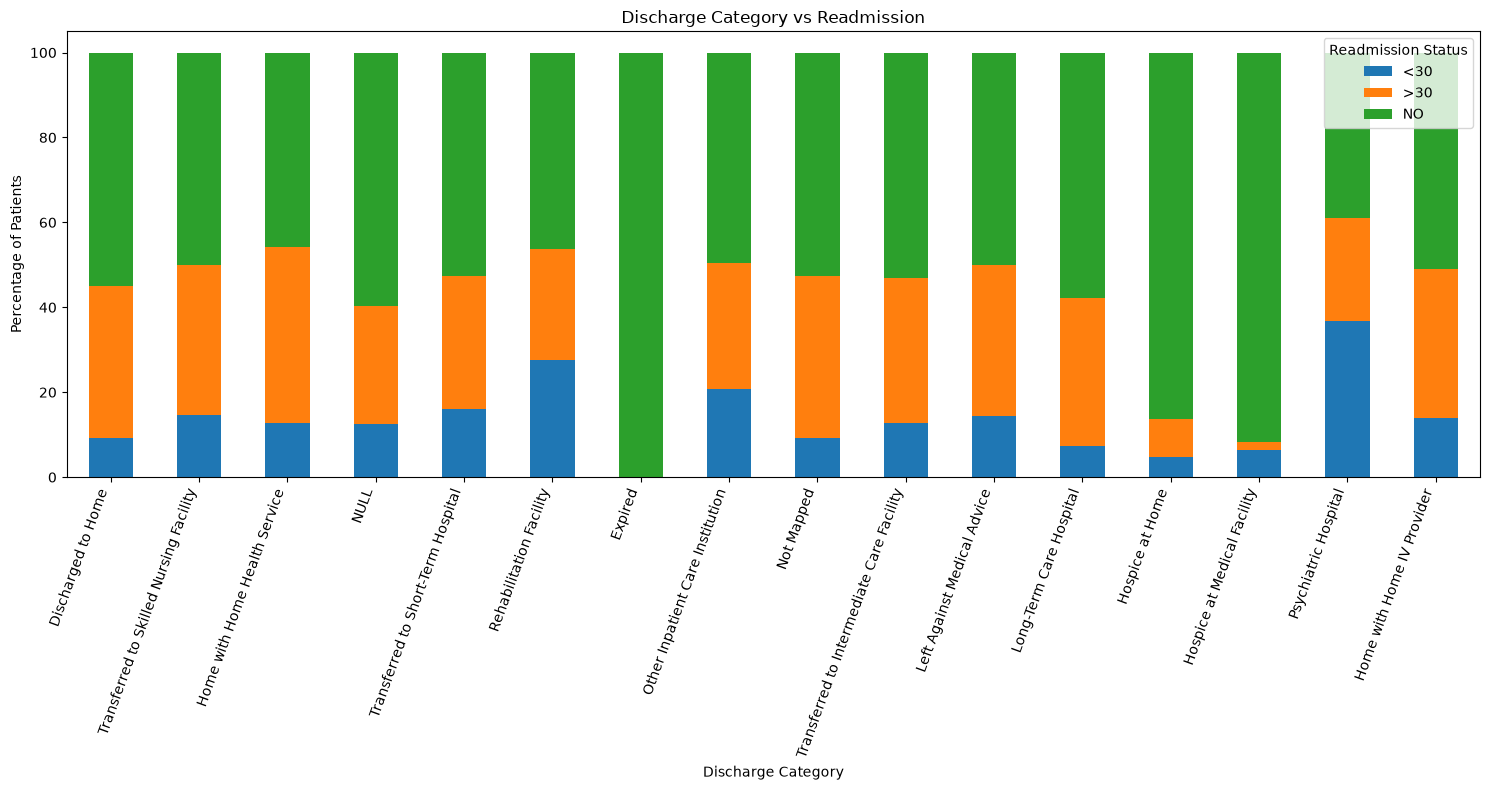

In [46]:
valid_categories = discharge_counts[
    discharge_counts >= 100
].index

discharge_readmission_filtered = discharge_readmission.loc[
    valid_categories
]

discharge_readmission_filtered.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 8)
)

plt.title("Discharge Category vs Readmission")
plt.xlabel("Discharge Category")
plt.ylabel("Percentage of Patients")
plt.xticks(rotation=70, ha="right")
plt.legend(title="Readmission Status")
plt.tight_layout()
plt.show()

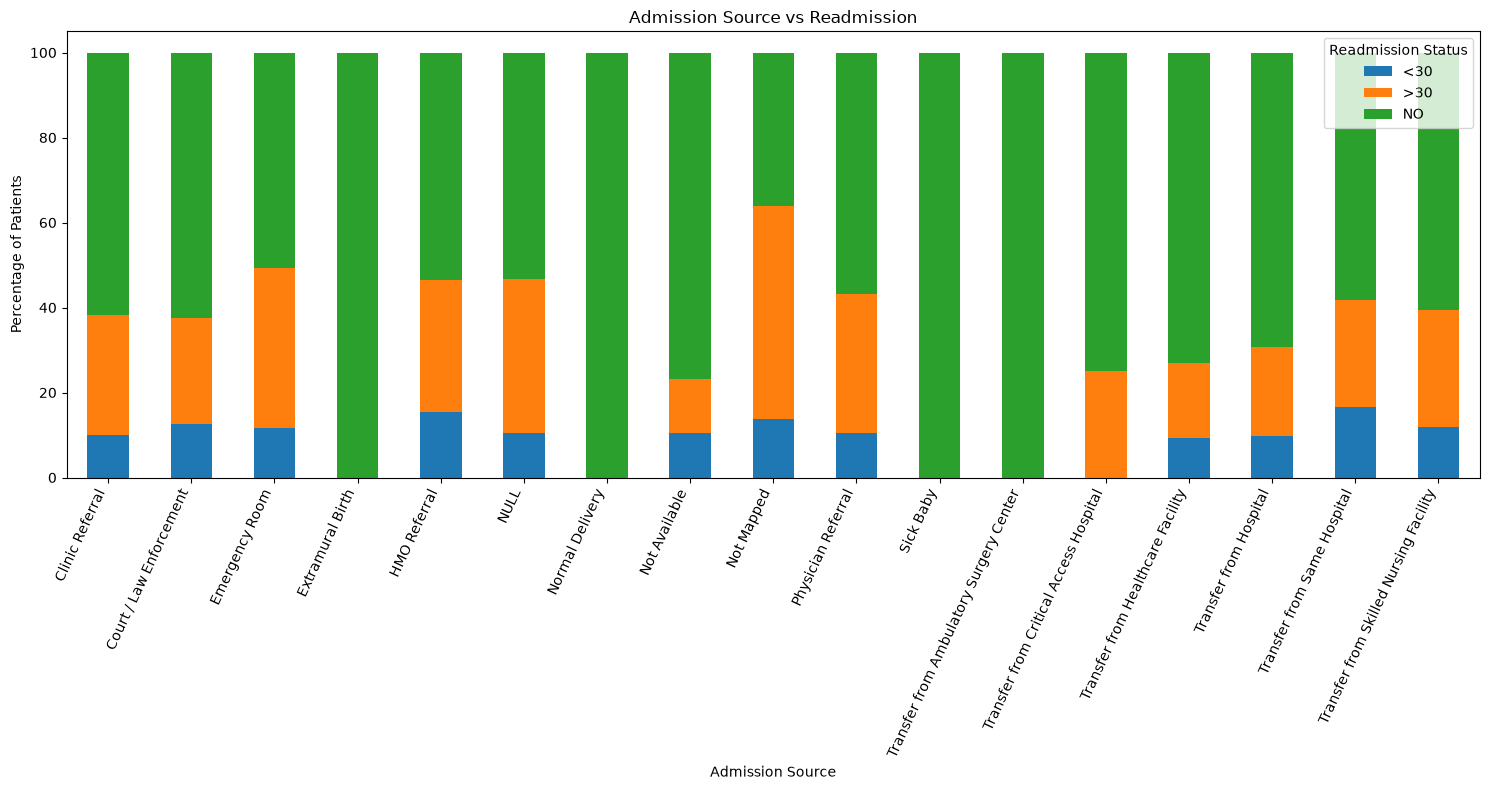

In [51]:
admission_readmission.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 8)
)

plt.title("Admission Source vs Readmission")
plt.xlabel("Admission Source")
plt.ylabel("Percentage of Patients")
plt.xticks(rotation=65, ha="right")
plt.legend(title="Readmission Status")
plt.tight_layout()
plt.show()

In [52]:
numerical_df = df.select_dtypes(include=["int64", "float64"])

correlation_matrix = numerical_df.corr()

display(correlation_matrix.round(2))

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
encounter_id,1.00,0.51,-0.16,-0.13,-0.11,-0.06,-0.03,-0.01,0.08,0.10,0.08,0.03,0.27
patient_nbr,0.51,1.00,-0.01,-0.14,-0.03,-0.02,0.02,-0.02,0.02,0.10,0.06,0.01,0.23
admission_type_id,-0.16,-0.01,1.00,0.08,0.11,-0.01,-0.14,0.13,0.08,0.03,-0.02,-0.04,-0.12
discharge_disposition_id,-0.13,-0.14,0.08,1.00,0.02,0.16,0.02,0.02,0.11,-0.01,-0.02,0.02,0.05
admission_source_id,-0.11,-0.03,0.11,0.02,1.00,-0.01,0.05,-0.14,-0.05,0.03,0.06,0.04,0.07
time_in_hospital,-0.06,-0.02,-0.01,0.16,-0.01,1.00,0.32,0.19,0.47,-0.01,-0.01,0.07,0.22
num_lab_procedures,-0.03,0.02,-0.14,0.02,0.05,0.32,1.00,0.06,0.27,-0.01,-0.00,0.04,0.15
num_procedures,-0.01,-0.02,0.13,0.02,-0.14,0.19,0.06,1.00,0.39,-0.02,-0.04,-0.07,0.07
num_medications,0.08,0.02,0.08,0.11,-0.05,0.47,0.27,0.39,1.00,0.05,0.01,0.06,0.26
number_outpatient,0.10,0.10,0.03,-0.01,0.03,-0.01,-0.01,-0.02,0.05,1.00,0.09,0.11,0.09


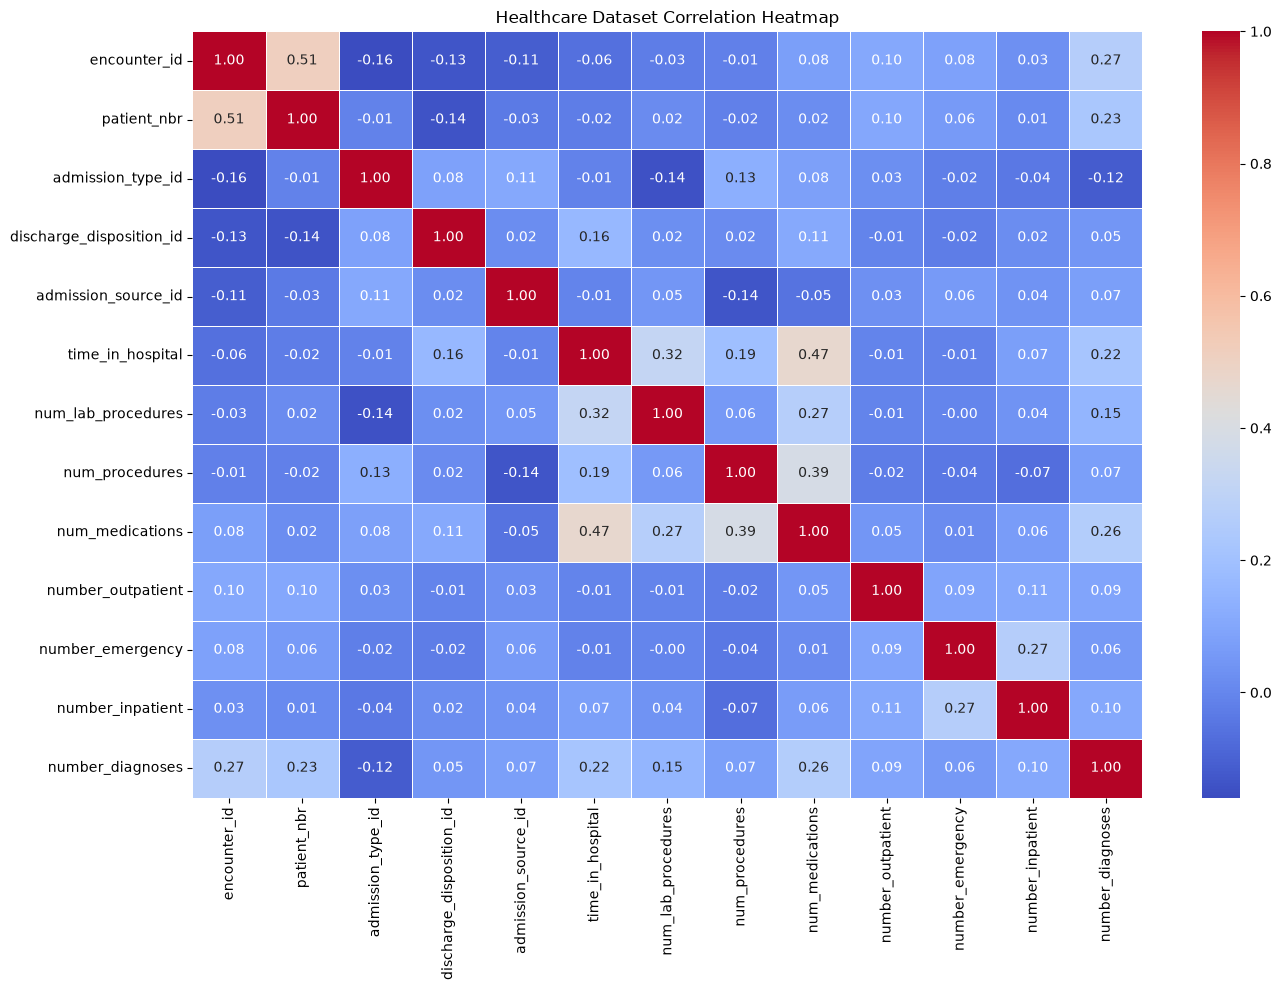

In [53]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Healthcare Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()

In [54]:
inpatient_readmission = pd.crosstab(
    df["number_inpatient"],
    df["readmitted"],
    normalize="index"
) * 100

display(inpatient_readmission.round(2))

readmitted,<30,>30,NO
number_inpatient,,,
0,8.44,30.06,61.51
1,12.92,41.84,45.24
2,17.43,47.50,35.06
3,20.29,49.43,30.28
4,23.61,50.62,25.77
5,31.40,48.65,19.95
6,34.58,49.58,15.83
7,35.45,45.52,19.03
8,44.37,46.36,9.27


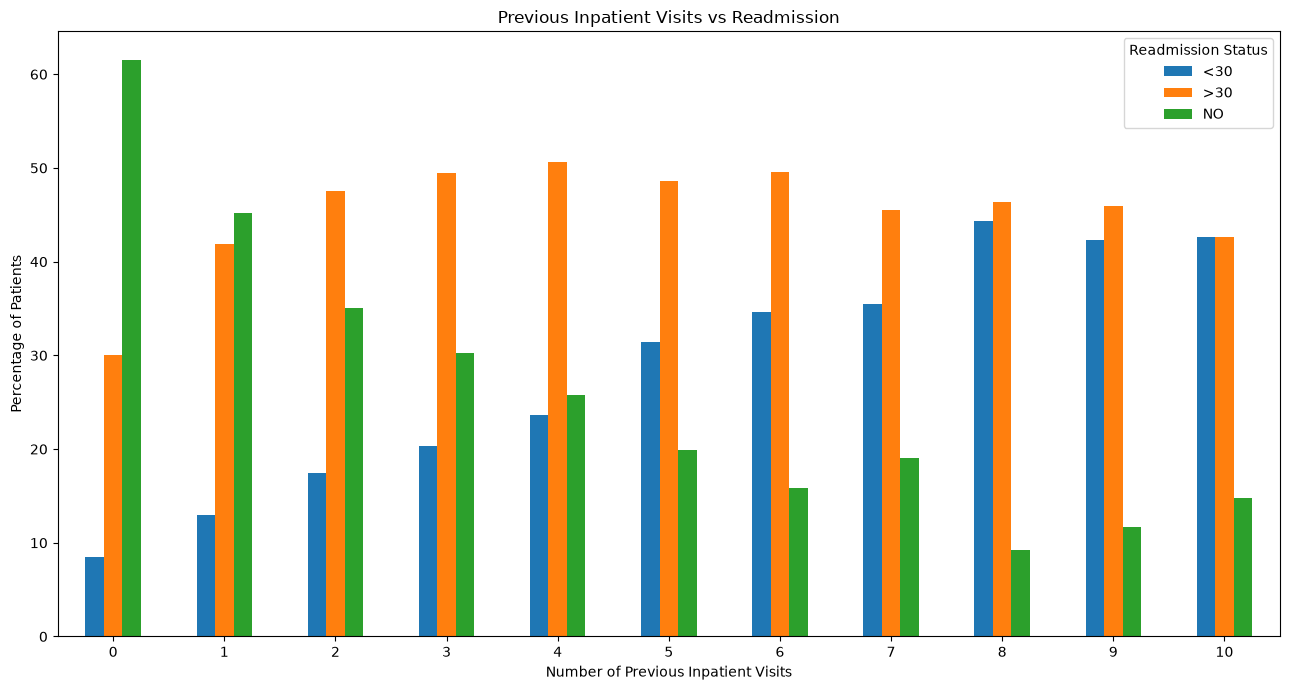

In [55]:
inpatient_readmission.loc[:10].plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title("Previous Inpatient Visits vs Readmission")
plt.xlabel("Number of Previous Inpatient Visits")
plt.ylabel("Percentage of Patients")
plt.xticks(rotation=0)
plt.legend(title="Readmission Status")
plt.tight_layout()
plt.show()

In [56]:
emergency_readmission = pd.crosstab(
    df["number_emergency"],
    df["readmitted"],
    normalize="index"
) * 100

display(emergency_readmission.round(2))

readmitted,<30,>30,NO
number_emergency,,,
0,10.47,33.42,56.11
1,14.35,44.94,40.71
2,18.27,48.82,32.91
3,20.28,51.59,28.14
4,30.75,50.80,18.45
5,24.48,55.73,19.79
6,23.40,60.64,15.96
7,26.03,64.38,9.59
8,32.00,50.00,18.00


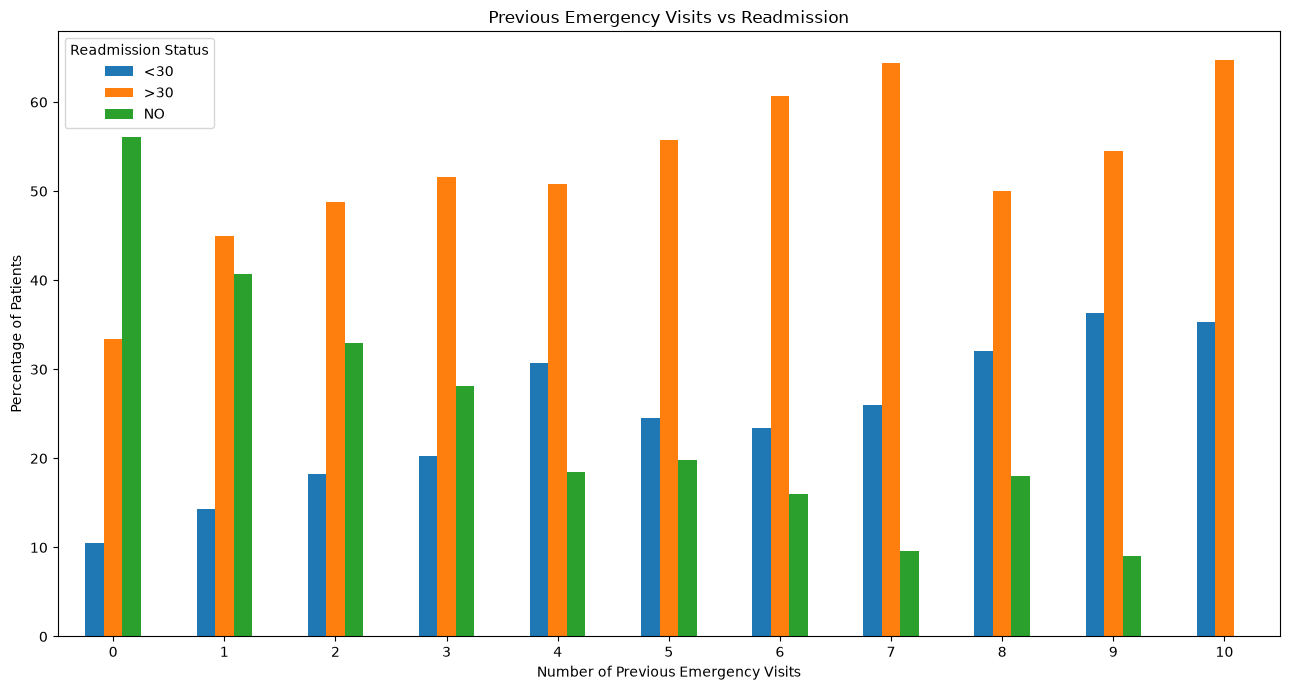

In [57]:
emergency_readmission.loc[:10].plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title("Previous Emergency Visits vs Readmission")
plt.xlabel("Number of Previous Emergency Visits")
plt.ylabel("Percentage of Patients")
plt.xticks(rotation=0)
plt.legend(title="Readmission Status")
plt.tight_layout()
plt.show()

In [58]:
outpatient_readmission = pd.crosstab(
    df["number_outpatient"],
    df["readmitted"],
    normalize="index"
) * 100

display(outpatient_readmission.round(2))

readmitted,<30,>30,NO
number_outpatient,,,
0,10.67,32.98,56.35
1,13.92,43.45,42.62
2,13.75,46.36,39.90
3,12.29,45.15,42.56
4,15.10,43.68,41.22
5,11.82,45.59,42.59
6,13.20,50.83,35.97
7,15.48,53.55,30.97
8,5.10,40.82,54.08


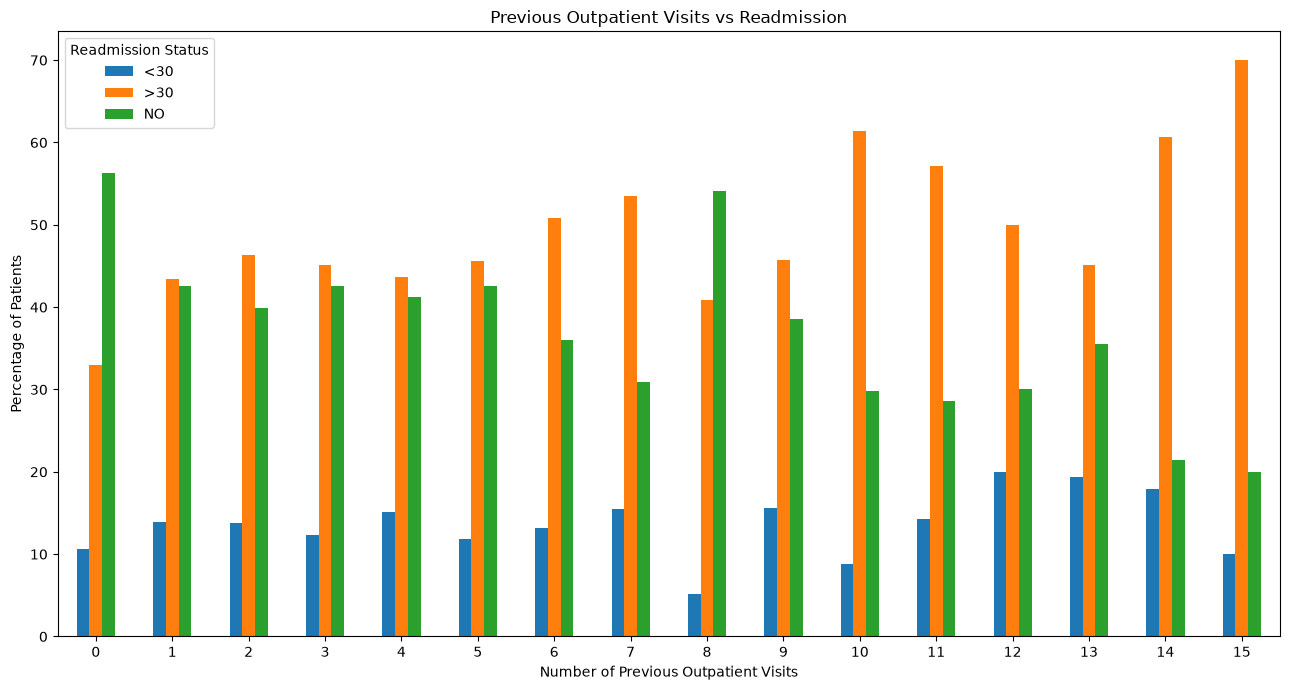

In [59]:
outpatient_readmission.loc[:15].plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title("Previous Outpatient Visits vs Readmission")
plt.xlabel("Number of Previous Outpatient Visits")
plt.ylabel("Percentage of Patients")
plt.xticks(rotation=0)
plt.legend(title="Readmission Status")
plt.tight_layout()
plt.show()

In [60]:
diagnosis_readmission = pd.crosstab(
    df["number_diagnoses"],
    df["readmitted"],
    normalize="index"
) * 100

display(diagnosis_readmission.round(2))

readmitted,<30,>30,NO
number_diagnoses,,,
1,5.94,17.81,76.26
2,6.06,26.78,67.16
3,7.37,26.91,65.71
4,8.25,29.00,62.74
5,9.15,26.30,64.55
6,10.41,33.43,56.16
7,10.77,35.91,53.32
8,11.81,35.78,52.41
9,12.38,38.20,49.42


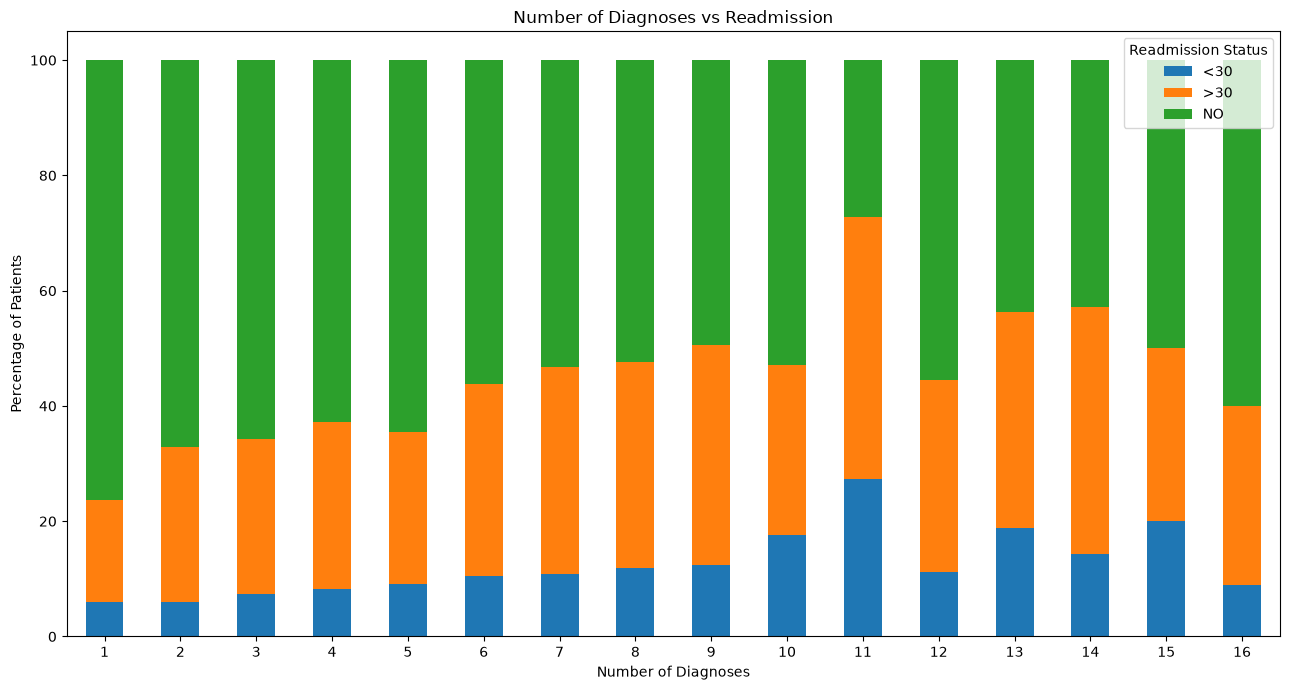

In [61]:
diagnosis_readmission.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7)
)

plt.title("Number of Diagnoses vs Readmission")
plt.xlabel("Number of Diagnoses")
plt.ylabel("Percentage of Patients")
plt.xticks(rotation=0)
plt.legend(title="Readmission Status")
plt.tight_layout()
plt.show()

In [62]:
question_marks = (df == "?").sum()

question_marks = question_marks[
    question_marks > 0
].sort_values(ascending=False)

display(question_marks.to_frame(name="Question_Mark_Count"))

,Question_Mark_Count
weight,98569
medical_specialty,49949
payer_code,40256
race,2273
diag_3,1423
diag_2,358
diag_1,21


In [63]:
df_clean = df.copy()

df_clean = df_clean.drop(columns=["weight"])

columns_to_clean = [
    "medical_specialty",
    "payer_code",
    "race",
    "diag_1",
    "diag_2",
    "diag_3"
]

for column in columns_to_clean:
    df_clean[column] = df_clean[column].replace("?", "Unknown")

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

Original Dataset Shape: (101766, 53)
Cleaned Dataset Shape: (101766, 52)


In [64]:
remaining_question_marks = (df_clean == "?").sum()

remaining_question_marks = remaining_question_marks[
    remaining_question_marks > 0
]

print("Remaining Question Marks:")
display(remaining_question_marks)

Remaining Question Marks:


Series([], dtype: int64)

In [65]:
missing_values_clean = df_clean.isnull().sum()

missing_values_clean = missing_values_clean[
    missing_values_clean > 0
].sort_values(ascending=False)

display(missing_values_clean.to_frame(name="Missing_Count"))

,Missing_Count
max_glu_serum,96420
A1Cresult,84748


In [66]:
df_clean["max_glu_serum"] = (
    df_clean["max_glu_serum"].fillna("Not Tested")
)

df_clean["A1Cresult"] = (
    df_clean["A1Cresult"].fillna("Not Tested")
)

print("Remaining Missing Values:",
      df_clean.isnull().sum().sum())

Remaining Missing Values: 0


In [67]:
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nData Types:")
print(df_clean.dtypes.value_counts())

print("\nFirst 5 Records:")
display(df_clean.head())

Cleaned Dataset Shape: (101766, 52)

Data Types:
str      39
int64    13
Name: count, dtype: int64

First 5 Records:


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,...,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,admission_type,discharge_category,admission_source
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Unknown,...,No,No,No,No,No,No,NO,NULL,Not Mapped,Physician Referral
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,Unknown,...,No,No,No,No,Ch,Yes,>30,Emergency,Discharged to Home,Emergency Room
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Unknown,...,No,No,No,No,No,Yes,NO,Emergency,Discharged to Home,Emergency Room
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,Unknown,...,No,No,No,No,Ch,Yes,NO,Emergency,Discharged to Home,Emergency Room
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,Unknown,...,No,No,No,No,Ch,Yes,NO,Emergency,Discharged to Home,Emergency Room


In [68]:
print("Duplicate Rows:", df_clean.duplicated().sum())

print(
    "Unique Encounters:",
    df_clean["encounter_id"].nunique()
)

print(
    "Unique Patients:",
    df_clean["patient_nbr"].nunique()
)

Duplicate Rows: 0
Unique Encounters: 101766
Unique Patients: 71518


In [69]:
df_clean.to_csv(
    "../data/diabetic_data_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [70]:
eda_report = """
# Healthcare Data Analysis — Exploratory Data Analysis

## 1. Project Overview
This project analyzes the Diabetes 130-US Hospitals dataset
covering hospital encounters from 1999 to 2008.

## 2. Dataset Overview
- Total hospital encounters: 101,766
- Unique patients: 71,518
- Original features: 50
- Duplicate records: 0

## 3. Data Cleaning
- Removed the weight column because approximately 97% of its values were missing.
- Replaced '?' markers with 'Unknown' in relevant categorical columns.
- Replaced missing max_glu_serum and A1Cresult values with 'Not Tested'.
- Preserved the original dataset.
- Saved the cleaned dataset separately.

## 4. Readmission Analysis
Readmission distribution:
- No readmission: 54,864
- Readmitted after 30 days: 35,545
- Readmitted within 30 days: 11,357

## 5. Key Findings

### Age
Older age groups represent a substantial portion of hospital encounters.
Readmission patterns vary across age groups.

### Gender
Female patients had a slightly higher readmission percentage
than male patients in this dataset.

### Hospital Stay
- Average hospital stay: approximately 4.40 days.
- Median hospital stay: 4 days.
- Most common hospital stay: 3 days.

Patients readmitted within 30 days had a higher average
hospital stay than patients who were not readmitted.

### Previous Hospital Visits
Patients with more previous inpatient and emergency visits
generally showed higher readmission percentages.

### Medical Activity
Hospital stays, medications, lab procedures, and diagnoses
showed different relationships with readmission.

### Medication
Patients receiving diabetes medication and patients whose
medication was changed showed different readmission patterns.

### Admission and Discharge
Emergency admissions and certain discharge categories
showed varying readmission patterns.

## 6. Correlation Analysis
Some notable positive correlations:
- Hospital stay and number of medications: approximately 0.47
- Number of procedures and medications: approximately 0.39
- Hospital stay and lab procedures: approximately 0.32

These correlations do not establish causation.

## 7. Important Limitations
- The dataset contains historical hospital records from 1999–2008.
- The analysis is observational and does not establish causal relationships.
- Some categories have very small sample sizes.
- Missing clinical test results may reflect tests that were not performed.
- Readmission patterns should not be interpreted as individual patient risk predictions.

## 8. Next Phase
Prepare the cleaned dataset for machine learning,
define the prediction target, and develop a baseline model.
"""

with open("../reports/eda_summary.md", "w", encoding="utf-8") as file:
    file.write(eda_report)

print("EDA report saved successfully!")

EDA report saved successfully!


In [71]:
print("Target Variable Distribution:")
print(df_clean["readmitted"].value_counts())

print("\nTarget Variable Percentages:")
print(
    df_clean["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target Variable Distribution:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Target Variable Percentages:
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


In [72]:
df_ml = df_clean.copy()

df_ml["target"] = (
    df_ml["readmitted"] == "<30"
).astype(int)

print("Binary Target Distribution:")
print(df_ml["target"].value_counts())

print("\nTarget Percentages:")
print(
    df_ml["target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Binary Target Distribution:
target
0    90409
1    11357
Name: count, dtype: int64

Target Percentages:
target
0    88.84
1    11.16
Name: proportion, dtype: float64


In [73]:
leakage_columns = [
    "readmitted",
    "target",
    "encounter_id",
    "patient_nbr"
]

print("Columns reserved for removal from ML features:")
print(leakage_columns)

print("\nCurrent Dataset Shape:", df_ml.shape)

Columns reserved for removal from ML features:
['readmitted', 'target', 'encounter_id', 'patient_nbr']

Current Dataset Shape: (101766, 53)


In [74]:
potential_leakage = [
    "discharge_disposition_id",
    "discharge_category"
]

print("Potential Leakage Columns:")
for column in potential_leakage:
    print(f"{column}: {df_ml[column].nunique()} unique values")

print("\nDischarge information is recorded at the end of a hospital stay.")

Potential Leakage Columns:
discharge_disposition_id: 26 unique values
discharge_category: 26 unique values

Discharge information is recorded at the end of a hospital stay.


In [75]:
drop_columns = [
    "readmitted",
    "target",
    "encounter_id",
    "patient_nbr",
    "discharge_disposition_id",
    "discharge_category"
]

X = df_ml.drop(columns=drop_columns)
y = df_ml["target"]

print("Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

print("\nRemaining Missing Values:", X.isnull().sum().sum())
print("Remaining '?' Values:", (X == "?").sum().sum())

Feature Dataset Shape: (101766, 47)
Target Dataset Shape: (101766,)

Remaining Missing Values: 0
Remaining '?' Values: 0


In [76]:
categorical_columns = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Columns:", len(categorical_columns))
print("Numerical Columns:", len(numerical_columns))

print("\nCategorical Features:")
print(categorical_columns)

print("\nNumerical Features:")
print(numerical_columns)

Categorical Columns: 37
Numerical Columns: 10

Categorical Features:
['race', 'gender', 'age', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'admission_type', 'admission_source']

Numerical Features:
['admission_type_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [77]:
X = X.drop(
    columns=[
        "admission_type_id",
        "admission_source_id"
    ]
)

categorical_columns = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Updated Feature Shape:", X.shape)
print("Categorical Columns:", len(categorical_columns))
print("Numerical Columns:", len(numerical_columns))

Updated Feature Shape: (101766, 45)
Categorical Columns: 37
Numerical Columns: 8


In [78]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training Features: (81412, 45)
Testing Features: (20354, 45)

Training Target Distribution:
target
0    88.84
1    11.16
Name: proportion, dtype: float64

Testing Target Distribution:
target
0    88.84
1    11.16
Name: proportion, dtype: float64


In [79]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_columns
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [80]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Data After Encoding:", X_train_processed.shape)
print("Testing Data After Encoding:", X_test_processed.shape)

print("\nPreprocessing completed successfully!")

Training Data After Encoding: (81412, 2390)
Testing Data After Encoding: (20354, 2390)

Preprocessing completed successfully!


In [81]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [82]:
y_pred = logistic_model.predict(X_test_processed)

y_pred_proba = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions Generated Successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions Generated Successfully!

First 10 Actual Values:
[0 0 0 1 1 0 0 0 0 0]

First 10 Predicted Values:
[1 0 0 1 0 0 0 0 1 1]


In [83]:
from sklearn.metrics import classification_report

print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Readmission",
            "Readmission Within 30 Days"
        ]
    )
)

Classification Report:

                            precision    recall  f1-score   support

            No Readmission       0.92      0.65      0.76     18083
Readmission Within 30 Days       0.17      0.55      0.26      2271

                  accuracy                           0.64     20354
                 macro avg       0.54      0.60      0.51     20354
              weighted avg       0.84      0.64      0.71     20354



Confusion Matrix:
[[11785  6298]
 [ 1018  1253]]


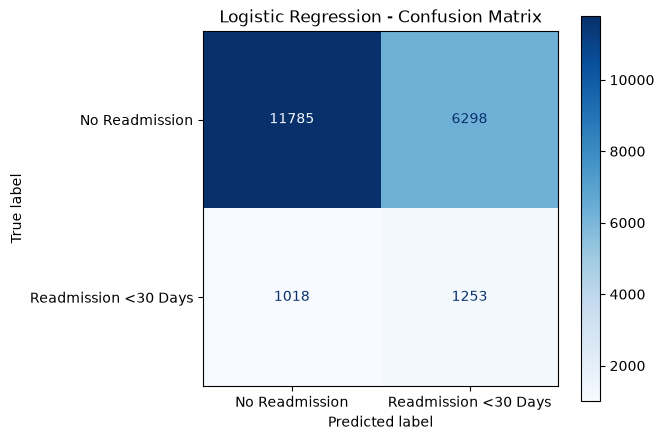

In [84]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Readmission",
        "Readmission <30 Days"
    ]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [85]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_test,
    y_pred_proba
)

print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.6424


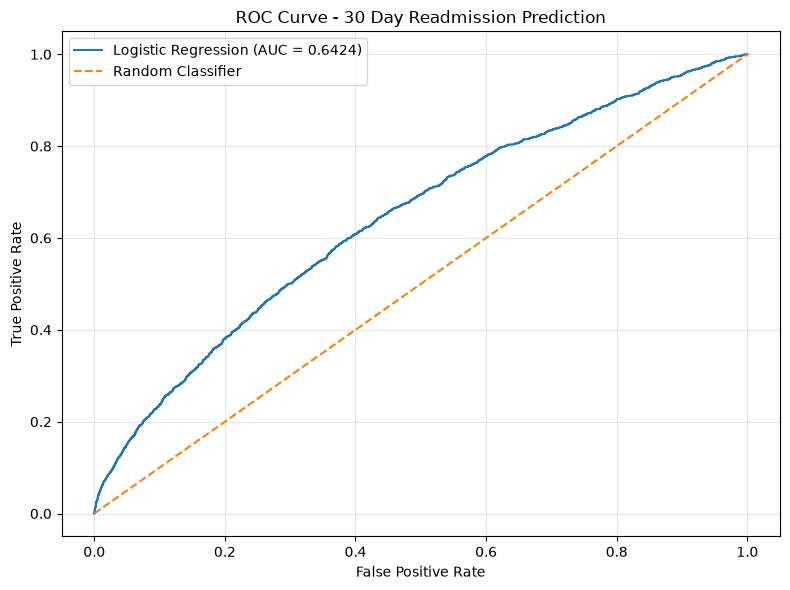

In [86]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_proba
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - 30 Day Readmission Prediction")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [87]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds_to_test = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds_to_test:

    y_threshold_pred = (
        y_pred_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_test, y_threshold_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_threshold_pred
    )

    f1 = f1_score(
        y_test, y_threshold_pred
    )

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")


Threshold: 0.3
Precision: 0.1212
Recall:    0.9163
F1 Score:  0.2141

Threshold: 0.4
Precision: 0.1391
Recall:    0.7869
F1 Score:  0.2364

Threshold: 0.5
Precision: 0.1659
Recall:    0.5517
F1 Score:  0.2551

Threshold: 0.6
Precision: 0.2036
Recall:    0.3162
F1 Score:  0.2477

Threshold: 0.7
Precision: 0.2712
Recall:    0.1590
F1 Score:  0.2004


In [88]:
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Sub-training Shape:", X_subtrain.shape)
print("Validation Shape:", X_val.shape)

print("\nValidation Target Distribution:")
print(y_val.value_counts(normalize=True).mul(100).round(2))

Sub-training Shape: (65129, 45)
Validation Shape: (16283, 45)

Validation Target Distribution:
target
0    88.84
1    11.16
Name: proportion, dtype: float64


In [89]:
X_subtrain_processed = preprocessor.fit_transform(X_subtrain)

X_val_processed = preprocessor.transform(X_val)

print("Sub-training Processed:", X_subtrain_processed.shape)
print("Validation Processed:", X_val_processed.shape)

print("\nValidation preprocessing completed!")

Sub-training Processed: (65129, 2302)
Validation Processed: (16283, 2302)

Validation preprocessing completed!


In [90]:
logistic_model_val = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model_val.fit(
    X_subtrain_processed,
    y_subtrain
)

print("Validation Logistic Regression trained successfully!")

Validation Logistic Regression trained successfully!


In [91]:
y_val_proba = logistic_model_val.predict_proba(
    X_val_processed
)[:, 1]

print("Validation probabilities generated!")

print("\nFirst 10 probabilities:")
print(y_val_proba[:10])

Validation probabilities generated!

First 10 probabilities:
[0.43734469 0.34031707 0.25579529 0.41661986 0.4790757  0.57649514
 0.46822499 0.50258162 0.63491094 0.42446276]


In [92]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:

    y_val_pred = (
        y_val_proba >= threshold
    ).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(y_val, y_val_pred),
        "F1_Score": f1_score(y_val, y_val_pred)
    })

validation_results = pd.DataFrame(results)

print(validation_results.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1_Score
       0.3     0.1222  0.9108    0.2155
       0.4     0.1386  0.7677    0.2348
       0.5     0.1664  0.5432    0.2548
       0.6     0.2068  0.3247    0.2527
       0.7     0.2491  0.1535    0.1900


In [93]:
# Fit preprocessor on complete training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform untouched test data

X_test_processed = preprocessor.transform(X_test)

print("Final training data:", X_train_processed.shape)
print("Final testing data:", X_test_processed.shape)
print("Selected threshold: 0.5")

Final training data: (81412, 2390)
Final testing data: (20354, 2390)
Selected threshold: 0.5


In [94]:
from sklearn.linear_model import LogisticRegression

final_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

final_model.fit(
    X_train_processed,
    y_train
)

print("Final Logistic Regression model trained successfully!")

Final Logistic Regression model trained successfully!


In [95]:
# Generate prediction probabilities
y_test_proba = final_model.predict_proba(
    X_test_processed
)[:, 1]

# Apply selected threshold
selected_threshold = 0.5

y_test_pred = (
    y_test_proba >= selected_threshold
).astype(int)

print("Final test predictions generated!")

print("\nFirst 10 actual values:")
print(y_test.values[:10])

print("\nFirst 10 predicted values:")
print(y_test_pred[:10])

Final test predictions generated!

First 10 actual values:
[0 0 0 1 1 0 0 0 0 0]

First 10 predicted values:
[1 0 0 1 0 0 0 0 1 1]


In [96]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "No Readmission",
            "Readmission Within 30 Days"
        ],
        digits=4
    )
)

                            precision    recall  f1-score   support

            No Readmission     0.9205    0.6517    0.7631     18083
Readmission Within 30 Days     0.1659    0.5517    0.2551      2271

                  accuracy                         0.6406     20354
                 macro avg     0.5432    0.6017    0.5091     20354
              weighted avg     0.8363    0.6406    0.7065     20354



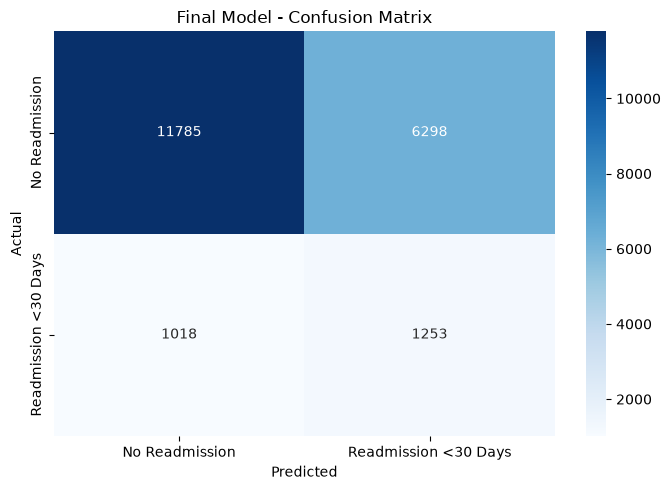

Confusion Matrix:
[[11785  6298]
 [ 1018  1253]]


In [97]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Readmission",
        "Readmission <30 Days"
    ],
    yticklabels=[
        "No Readmission",
        "Readmission <30 Days"
    ]
)

plt.title("Final Model - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

Final Test ROC-AUC: 0.6424


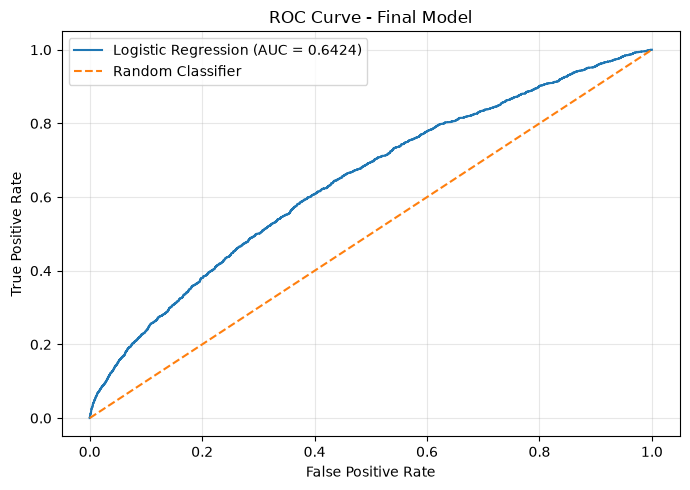

In [101]:
from sklearn.metrics import roc_auc_score, roc_curve

roc_auc = roc_auc_score(
    y_test,
    y_test_proba
)

print("Final Test ROC-AUC:", round(roc_auc, 4))

fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    y_test_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../images/logistic_regression_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "../images/logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "../images/logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [103]:
evaluation_results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Threshold": 0.5,
    "Accuracy": 0.6406,
    "Precision": 0.1659,
    "Recall": 0.5517,
    "F1_Score": 0.2551,
    "ROC_AUC": 0.6424
}])

evaluation_results.to_csv(
    "../reports/model_evaluation_results.csv",
    index=False
)

print("Model evaluation results saved successfully!")

Model evaluation results saved successfully!


In [104]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model initialized successfully!")

Random Forest model initialized successfully!


In [105]:
random_forest_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [106]:
# Generate prediction probabilities

rf_test_proba = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

# Apply selected threshold

rf_test_pred = (
    rf_test_proba >= 0.5
).astype(int)

print("Random Forest predictions generated!")

print("\nFirst 10 actual values:")
print(y_test.values[:10])

print("\nFirst 10 predicted values:")
print(rf_test_pred[:10])

Random Forest predictions generated!

First 10 actual values:
[0 0 0 1 1 0 0 0 0 0]

First 10 predicted values:
[1 0 0 1 0 0 0 0 1 1]


In [107]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        rf_test_pred,
        target_names=[
            "No Readmission",
            "Readmission Within 30 Days"
        ],
        digits=4
    )
)

                            precision    recall  f1-score   support

            No Readmission     0.9221    0.6522    0.7640     18083
Readmission Within 30 Days     0.1685    0.5614    0.2593      2271

                  accuracy                         0.6420     20354
                 macro avg     0.5453    0.6068    0.5116     20354
              weighted avg     0.8380    0.6420    0.7077     20354



Random Forest Test ROC-AUC: 0.6548


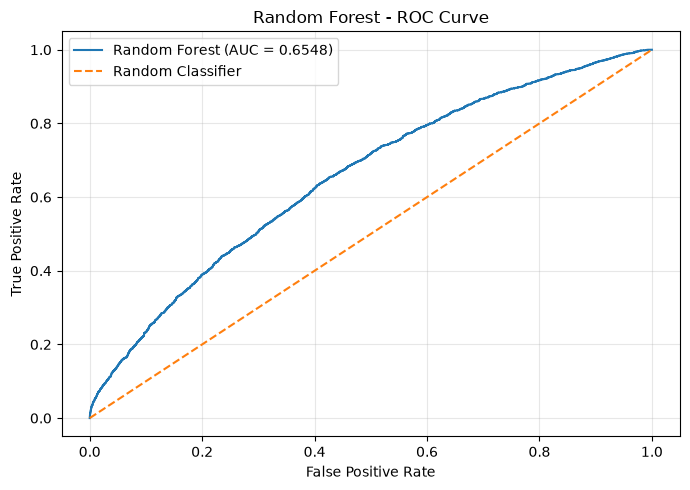

In [109]:
from sklearn.metrics import roc_auc_score, roc_curve

rf_roc_auc = roc_auc_score(
    y_test,
    rf_test_proba
)

print(
    "Random Forest Test ROC-AUC:",
    round(rf_roc_auc, 4)
)

rf_fpr, rf_tpr, rf_thresholds = roc_curve(
    y_test,
    rf_test_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../images/random_forest_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [110]:
model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.6406,
        "Precision": 0.1659,
        "Recall": 0.5517,
        "F1_Score": 0.2551,
        "ROC_AUC": 0.6424
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.6420,
        "Precision": 0.1685,
        "Recall": 0.5614,
        "F1_Score": 0.2593,
        "ROC_AUC": 0.6548
    }
])

model_comparison.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")
print(model_comparison.to_string(index=False))

Model comparison saved successfully!
              Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
Logistic Regression    0.6406     0.1659  0.5517    0.2551   0.6424
      Random Forest    0.6420     0.1685  0.5614    0.2593   0.6548


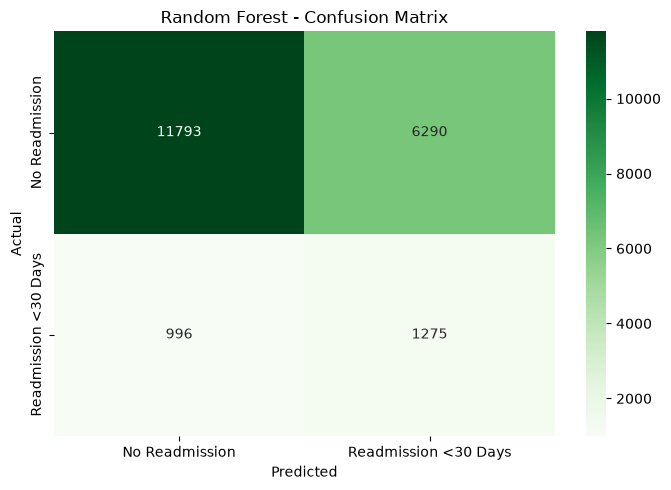

Random Forest Confusion Matrix:
[[11793  6290]
 [  996  1275]]


In [111]:
rf_cm = confusion_matrix(
    y_test,
    rf_test_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[
        "No Readmission",
        "Readmission <30 Days"
    ],
    yticklabels=[
        "No Readmission",
        "Readmission <30 Days"
    ]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    "../images/random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Random Forest Confusion Matrix:")
print(rf_cm)

In [112]:
feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Important Features:")
print(feature_importance.head(20).to_string(index=False))

Top 20 Important Features:
                  Feature  Importance
    num__number_inpatient    0.174888
    num__number_emergency    0.040048
     num__num_medications    0.037387
    num__time_in_hospital    0.036685
    num__number_diagnoses    0.034261
  num__num_lab_procedures    0.024131
   num__number_outpatient    0.017464
          cat__diag_2_250    0.013455
          cat__diag_3_250    0.013436
      num__num_procedures    0.013395
          cat__insulin_No    0.011019
          cat__diag_3_401    0.010313
        cat__insulin_Down    0.010035
          cat__diag_1_786    0.009730
          cat__diag_1_V58    0.009505
        cat__metformin_No    0.008479
      cat__diabetesMed_No    0.008193
     cat__diabetesMed_Yes    0.008073
cat__A1Cresult_Not Tested    0.006819
  cat__payer_code_Unknown    0.006692


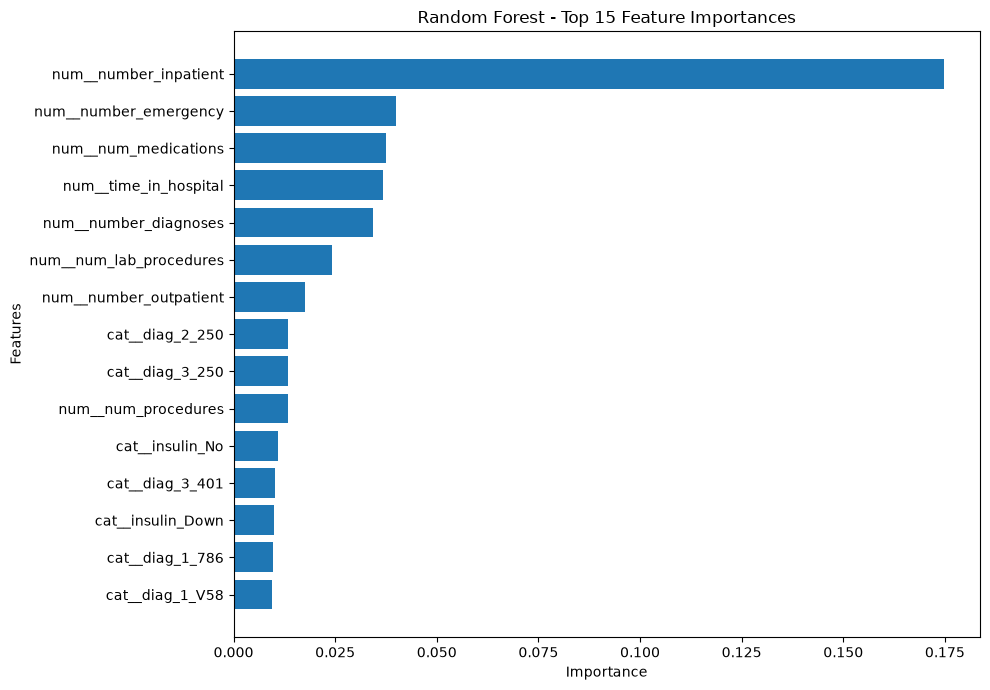

In [113]:
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()

plt.savefig(
    "../images/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [114]:
feature_importance.head(20).to_csv(
    "../reports/random_forest_feature_importance.csv",
    index=False
)

print("Feature importance report saved successfully!")

Feature importance report saved successfully!


In [115]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)
print("XGBoost imported successfully!")

XGBoost version: 3.4.1
XGBoost imported successfully!


In [116]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=7.96,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model initialized successfully!")

XGBoost model initialized successfully!


In [117]:
xgb_model.fit(
    X_train_processed,
    y_train
)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [118]:
# Generate prediction probabilities

xgb_test_proba = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# Apply the same threshold

xgb_test_pred = (
    xgb_test_proba >= 0.5
).astype(int)

print("XGBoost predictions generated!")

print("\nFirst 10 actual values:")
print(y_test.values[:10])

print("\nFirst 10 predicted values:")
print(xgb_test_pred[:10])

XGBoost predictions generated!

First 10 actual values:
[0 0 0 1 1 0 0 0 0 0]

First 10 predicted values:
[1 0 0 1 0 0 0 0 1 1]


In [119]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        xgb_test_pred,
        target_names=[
            "No Readmission",
            "Readmission Within 30 Days"
        ],
        digits=4
    )
)

                            precision    recall  f1-score   support

            No Readmission     0.9210    0.6862    0.7864     18083
Readmission Within 30 Days     0.1753    0.5310    0.2636      2271

                  accuracy                         0.6689     20354
                 macro avg     0.5481    0.6086    0.5250     20354
              weighted avg     0.8378    0.6689    0.7281     20354



XGBoost Test ROC-AUC: 0.6552


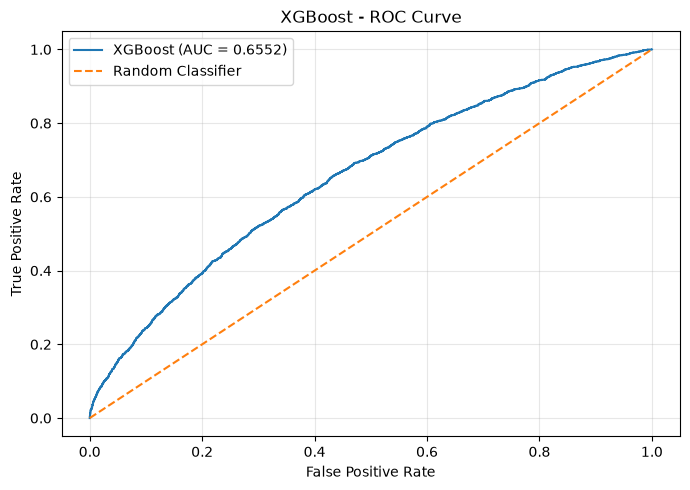

In [121]:
from sklearn.metrics import roc_auc_score, roc_curve

xgb_roc_auc = roc_auc_score(
    y_test,
    xgb_test_proba
)

print(
    "XGBoost Test ROC-AUC:",
    round(xgb_roc_auc, 4)
)

xgb_fpr, xgb_tpr, xgb_thresholds = roc_curve(
    y_test,
    xgb_test_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC = {xgb_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../images/xgboost_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

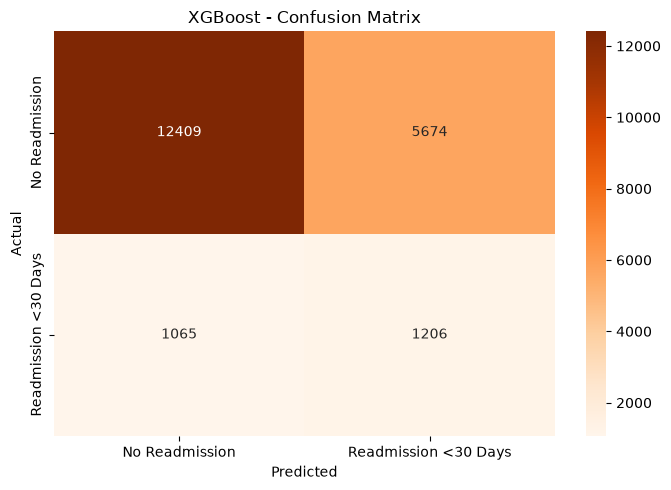

XGBoost Confusion Matrix:
[[12409  5674]
 [ 1065  1206]]


In [122]:
xgb_cm = confusion_matrix(
    y_test,
    xgb_test_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=[
        "No Readmission",
        "Readmission <30 Days"
    ],
    yticklabels=[
        "No Readmission",
        "Readmission <30 Days"
    ]
)

plt.title("XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    "../images/xgboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("XGBoost Confusion Matrix:")
print(xgb_cm)

In [123]:
xgb_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

xgb_importance.head(20)


,Feature,Importance
6,num__number_inpatient,0.022306
390,cat__diag_1_434,0.006374
673,cat__diag_1_820,0.006229
803,cat__diag_1_V57,0.005653
641,cat__diag_1_786,0.005640
5,num__number_emergency,0.005542
804,cat__diag_1_V58,0.005174
996,cat__diag_2_342,0.004997
259,cat__diag_1_278,0.004884
2242,cat__diag_3_Unknown,0.004561


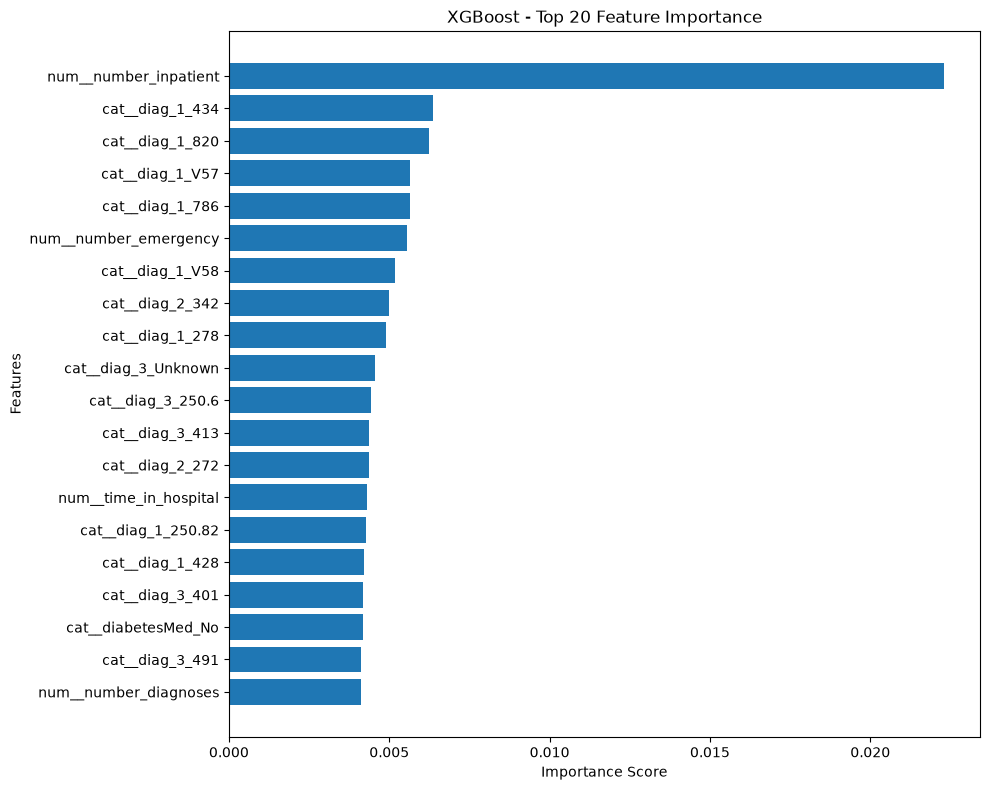

XGBoost feature importance graph saved successfully!


In [124]:
plt.figure(figsize=(10, 8))

top_features = xgb_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("XGBoost - Top 20 Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()

plt.savefig(
    "../images/xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("XGBoost feature importance graph saved successfully!")

In [125]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [0.6406, 0.6420, 0.6689],
    "Precision": [0.1659, 0.1685, 0.1753],
    "Recall": [0.5517, 0.5614, 0.5310],
    "F1_Score": [0.2551, 0.2593, 0.2636],
    "ROC_AUC": [0.6424, 0.6548, 0.6552]
})

model_comparison.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [126]:
from sklearn.model_selection import GroupShuffleSplit

groups = df_ml["patient_nbr"]

group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])

print("Training Shape:", X_train_group.shape)
print("Testing Shape:", X_test_group.shape)

print("Training Patients:", len(train_patients))
print("Testing Patients:", len(test_patients))

print("Overlapping Patients:", len(train_patients.intersection(test_patients)))

Training Shape: (81613, 45)
Testing Shape: (20153, 45)
Training Patients: 57214
Testing Patients: 14304
Overlapping Patients: 0


In [127]:
X_train_group_processed = preprocessor.fit_transform(
    X_train_group
)

X_test_group_processed = preprocessor.transform(
    X_test_group
)

print("Training Processed Shape:", X_train_group_processed.shape)
print("Testing Processed Shape:", X_test_group_processed.shape)

Training Processed Shape: (81613, 2397)
Testing Processed Shape: (20153, 2397)


In [128]:
logistic_group_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_group_model.fit(
    X_train_group_processed,
    y_train_group
)

logistic_group_proba = logistic_group_model.predict_proba(
    X_test_group_processed
)[:, 1]

logistic_group_pred = (
    logistic_group_proba >= 0.5
).astype(int)

print("Patient-Level Logistic Regression trained successfully!")

Patient-Level Logistic Regression trained successfully!


In [129]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Patient-Level Logistic Regression Report:\n")

print(
    classification_report(
        y_test_group,
        logistic_group_pred,
        target_names=[
            "No Readmission",
            "Readmission Within 30 Days"
        ]
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_group,
        logistic_group_pred
    )
)

logistic_group_auc = roc_auc_score(
    y_test_group,
    logistic_group_proba
)

print("Patient-Level ROC-AUC:", round(logistic_group_auc, 4))

Patient-Level Logistic Regression Report:

                            precision    recall  f1-score   support

            No Readmission       0.92      0.65      0.76     18002
Readmission Within 30 Days       0.15      0.53      0.24      2151

                  accuracy                           0.64     20153
                 macro avg       0.54      0.59      0.50     20153
              weighted avg       0.84      0.64      0.71     20153

Confusion Matrix:
[[11736  6266]
 [ 1011  1140]]
Patient-Level ROC-AUC: 0.6295


In [130]:
rf_group_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_group_model.fit(
    X_train_group_processed,
    y_train_group
)

rf_group_proba = rf_group_model.predict_proba(
    X_test_group_processed
)[:, 1]

rf_group_pred = (
    rf_group_proba >= 0.5
).astype(int)

print("Patient-Level Random Forest trained successfully!")

Patient-Level Random Forest trained successfully!


In [131]:
print("Patient-Level Random Forest Report:\n")

print(
    classification_report(
        y_test_group,
        rf_group_pred,
        target_names=[
            "No Readmission",
            "Readmission Within 30 Days"
        ]
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_group,
        rf_group_pred
    )
)

rf_group_auc = roc_auc_score(
    y_test_group,
    rf_group_proba
)

print("Patient-Level ROC-AUC:", round(rf_group_auc, 4))

Patient-Level Random Forest Report:

                            precision    recall  f1-score   support

            No Readmission       0.92      0.65      0.76     18002
Readmission Within 30 Days       0.16      0.55      0.25      2151

                  accuracy                           0.64     20153
                 macro avg       0.54      0.60      0.50     20153
              weighted avg       0.84      0.64      0.71     20153

Confusion Matrix:
[[11663  6339]
 [  961  1190]]
Patient-Level ROC-AUC: 0.644


In [132]:
xgb_group_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=7.96,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_group_model.fit(
    X_train_group_processed,
    y_train_group
)

xgb_group_proba = xgb_group_model.predict_proba(
    X_test_group_processed
)[:, 1]

xgb_group_pred = (
    xgb_group_proba >= 0.5
).astype(int)

print("Patient-Level XGBoost trained successfully!")

Patient-Level XGBoost trained successfully!


In [133]:
print("Patient-Level XGBoost Report:\n")

print(
    classification_report(
        y_test_group,
        xgb_group_pred,
        target_names=[
            "No Readmission",
            "Readmission Within 30 Days"
        ]
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_group,
        xgb_group_pred
    )
)

xgb_group_auc = roc_auc_score(
    y_test_group,
    xgb_group_proba
)

print("Patient-Level ROC-AUC:", round(xgb_group_auc, 4))

Patient-Level XGBoost Report:

                            precision    recall  f1-score   support

            No Readmission       0.92      0.67      0.78     18002
Readmission Within 30 Days       0.16      0.53      0.25      2151

                  accuracy                           0.66     20153
                 macro avg       0.54      0.60      0.51     20153
              weighted avg       0.84      0.66      0.72     20153

Confusion Matrix:
[[12131  5871]
 [ 1015  1136]]
Patient-Level ROC-AUC: 0.6438


In [134]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

group_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test_group, logistic_group_pred),
        accuracy_score(y_test_group, rf_group_pred),
        accuracy_score(y_test_group, xgb_group_pred)
    ],
    "Precision": [
        precision_score(y_test_group, logistic_group_pred),
        precision_score(y_test_group, rf_group_pred),
        precision_score(y_test_group, xgb_group_pred)
    ],
    "Recall": [
        recall_score(y_test_group, logistic_group_pred),
        recall_score(y_test_group, rf_group_pred),
        recall_score(y_test_group, xgb_group_pred)
    ],
    "F1_Score": [
        f1_score(y_test_group, logistic_group_pred),
        f1_score(y_test_group, rf_group_pred),
        f1_score(y_test_group, xgb_group_pred)
    ],
    "ROC_AUC": [
        logistic_group_auc,
        rf_group_auc,
        xgb_group_auc
    ]
})

group_model_comparison.to_csv(
    "../reports/patient_level_model_comparison.csv",
    index=False
)

group_model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.6389,0.1539,0.5300,0.2386,0.6295
1,Random Forest,0.6378,0.1581,0.5532,0.2459,0.6440
2,XGBoost,0.6583,0.1621,0.5281,0.2481,0.6438


In [135]:
print("Patient-Level Model Comparison:")
print(group_model_comparison.round(4))

print("\nSaving Results...")

group_model_comparison.to_csv(
    "../reports/patient_level_model_comparison.csv",
    index=False
)

print("Patient-level comparison saved successfully!")

Patient-Level Model Comparison:
                 Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
0  Logistic Regression    0.6389     0.1539  0.5300    0.2386   0.6295
1        Random Forest    0.6378     0.1581  0.5532    0.2459   0.6440
2              XGBoost    0.6583     0.1621  0.5281    0.2481   0.6438

Saving Results...
Patient-level comparison saved successfully!


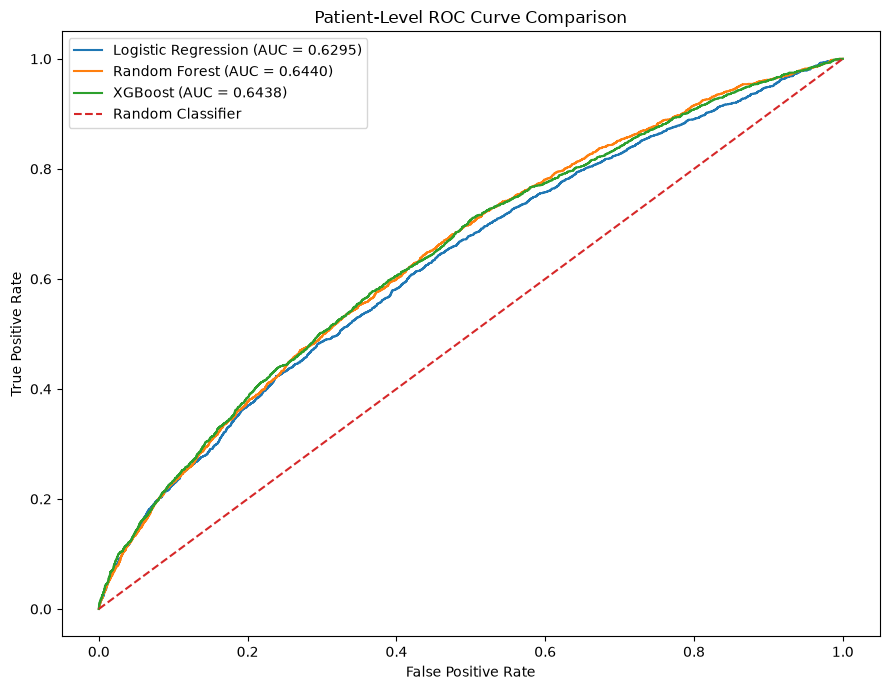

Patient-level ROC comparison saved successfully!


In [136]:
from sklearn.metrics import roc_curve

lr_fpr, lr_tpr, _ = roc_curve(
    y_test_group, logistic_group_proba
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_test_group, rf_group_proba
)

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test_group, xgb_group_proba
)

plt.figure(figsize=(9, 7))

plt.plot(
    lr_fpr, lr_tpr,
    label=f"Logistic Regression (AUC = {logistic_group_auc:.4f})"
)

plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {rf_group_auc:.4f})"
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f"XGBoost (AUC = {xgb_group_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("Patient-Level ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.tight_layout()

plt.savefig(
    "../images/patient_level_roc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Patient-level ROC comparison saved successfully!")

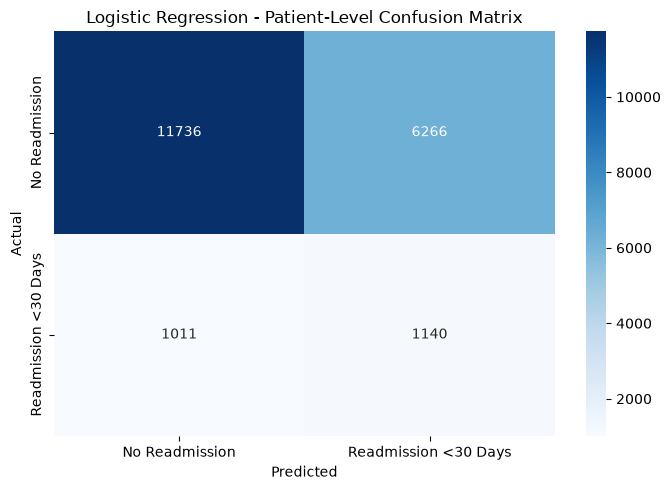

patient_logistic_confusion_matrix.png saved successfully!


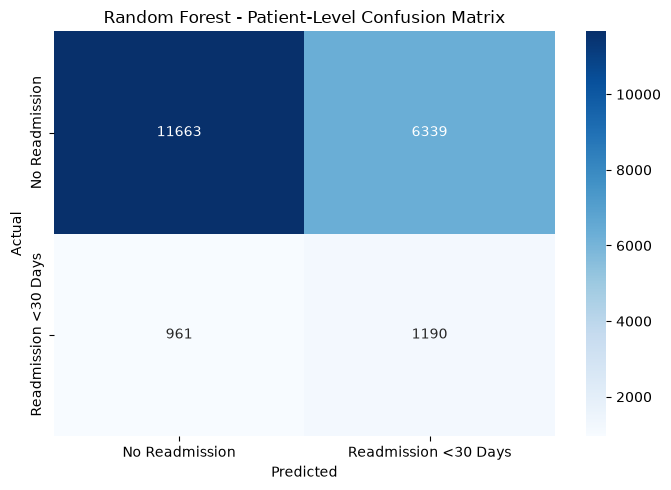

patient_random_forest_confusion_matrix.png saved successfully!


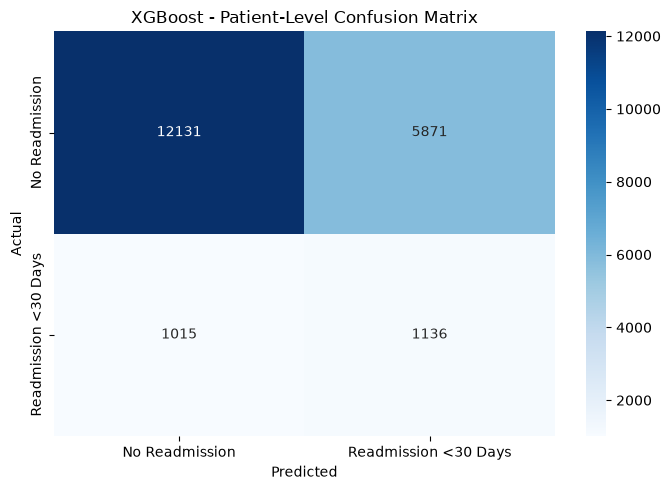

patient_xgboost_confusion_matrix.png saved successfully!


In [137]:
models_cm = {
    "Logistic Regression": (
        y_test_group, logistic_group_pred,
        "patient_logistic_confusion_matrix.png"
    ),
    "Random Forest": (
        y_test_group, rf_group_pred,
        "patient_random_forest_confusion_matrix.png"
    ),
    "XGBoost": (
        y_test_group, xgb_group_pred,
        "patient_xgboost_confusion_matrix.png"
    )
}

for model_name, (actual, predicted, filename) in models_cm.items():

    cm = confusion_matrix(actual, predicted)

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Readmission", "Readmission <30 Days"],
        yticklabels=["No Readmission", "Readmission <30 Days"]
    )

    plt.title(f"{model_name} - Patient-Level Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()

    plt.savefig(
        f"../images/{filename}",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"{filename} saved successfully!")

In [138]:
from pathlib import Path

report_content = """
# Healthcare Readmission Prediction
## Machine Learning Model Evaluation Report

### 1. Project Objective

The objective of this project is to analyze historical hospital encounter
data and develop machine learning models to estimate the likelihood of
a patient's readmission within 30 days.

This is an educational research project and is not intended for clinical
decision-making.

### 2. Dataset Overview

- Dataset: Diabetes 130-US Hospitals for Years 1999-2008
- Source: UCI Machine Learning Repository
- Original encounters: 101,766
- Unique patients: 71,518
- Target: Readmission within 30 days

### 3. Data Preparation

The following preprocessing operations were performed:

- Removed the weight column because approximately 96.86% of its values
  were missing.
- Replaced question-mark markers with Unknown in relevant categorical
  columns.
- Replaced missing max_glu_serum and A1Cresult values with Not Tested.
- Created readable admission type, admission source, and discharge
  category labels.
- Removed identifier columns from model features.
- Excluded readmission outcome and discharge disposition information
  from the predictors.
- Applied StandardScaler to numerical features.
- Applied OneHotEncoder to categorical features.

The binary target was defined as:

- 1: Readmitted within 30 days (<30)
- 0: Not readmitted within 30 days (NO or >30)

Positive class: 11,357 encounters (11.16%)
Negative class: 90,409 encounters (88.84%)

### 4. Model Evaluation Methodology

Three classification algorithms were evaluated:

1. Logistic Regression
2. Random Forest
3. XGBoost

A patient-level train/test split was performed using GroupShuffleSplit.

- Training encounters: 81,613
- Testing encounters: 20,153
- Training patients: 57,214
- Testing patients: 14,304
- Overlapping patients: 0

The patient identifier was used only for grouping and was not included
as a model feature.

Preprocessing was fitted on the training data and applied to the
testing data. All three models used a classification threshold of 0.5.

### 5. Patient-Level Model Results

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.6389 | 0.1539 | 0.5300 | 0.2386 | 0.6295 |
| Random Forest | 0.6378 | 0.1581 | 0.5532 | 0.2459 | 0.6440 |
| XGBoost | 0.6583 | 0.1621 | 0.5281 | 0.2481 | 0.6438 |

### 6. Model Interpretation

- XGBoost achieved the highest accuracy (65.83%), precision (16.21%),
  and F1-score (0.2481).
- Random Forest achieved the highest recall (55.32%) and ROC-AUC (0.6440).
- Logistic Regression provided a baseline for comparison.
- Random Forest and XGBoost showed very similar ROC-AUC values.

XGBoost achieved the highest F1-score, but the difference from Random
Forest was small. Therefore, neither model can be considered a
definitively superior or clinically reliable solution.

### 7. Important Limitations

- The dataset is historical and covers hospital encounters from
  1999 to 2008.
- The target classes are imbalanced.
- Positive-class precision is low, meaning many predicted readmissions
  are false positives.
- The evaluation uses a random patient-level split, not a temporal
  split. Performance on future time periods has not been established.
- Some predictors, such as length of stay and treatment activity,
  become available during the hospital encounter. The model should
  therefore be interpreted as a retrospective discharge-time
  risk-estimation prototype, not an admission-time prediction system.
- The test results were used to compare the three candidate models.
  An independent external dataset or a separate final holdout would
  be needed for an unbiased final performance estimate.
- The model has not undergone clinical validation.

### 8. Future Improvements

- Perform patient-grouped cross-validation.
- Evaluate threshold selection using training/validation data only.
- Investigate class imbalance and precision-recall trade-offs.
- Explore feature selection and hyperparameter optimization.
- Perform temporal and external validation.
- Improve interpretability using SHAP or other explainability methods.

### 9. Conclusion

This project demonstrates a complete machine learning workflow for
historical hospital readmission analysis, including data cleaning,
exploratory analysis, feature preprocessing, model training,
patient-level evaluation, and model comparison.

XGBoost achieved the highest F1-score in the current patient-level
comparison, while Random Forest achieved the highest recall and
ROC-AUC. The results demonstrate the challenges of predicting
30-day readmission in an imbalanced healthcare dataset.

The project is an educational research prototype and requires
further validation before any real-world healthcare application.
"""

report_path = Path("../reports/model_evaluation.md")

report_path.write_text(
    report_content,
    encoding="utf-8"
)

print("Model evaluation report created successfully!")
print("File:", report_path.resolve())

Model evaluation report created successfully!
File: C:\Users\Person-AL-Computer\Desktop\Six Projects\healthcare-data-analysis\reports\model_evaluation.md


In [139]:
from pathlib import Path

report_path = Path("../reports/model_evaluation.md")

print(report_path.read_text(encoding="utf-8"))


# Healthcare Readmission Prediction
## Machine Learning Model Evaluation Report

### 1. Project Objective

The objective of this project is to analyze historical hospital encounter
data and develop machine learning models to estimate the likelihood of
a patient's readmission within 30 days.

This is an educational research project and is not intended for clinical
decision-making.

### 2. Dataset Overview

- Dataset: Diabetes 130-US Hospitals for Years 1999-2008
- Source: UCI Machine Learning Repository
- Original encounters: 101,766
- Unique patients: 71,518
- Target: Readmission within 30 days

### 3. Data Preparation

The following preprocessing operations were performed:

- Removed the weight column because approximately 96.86% of its values
  were missing.
- Replaced question-mark markers with Unknown in relevant categorical
  columns.
- Replaced missing max_glu_serum and A1Cresult values with Not Tested.
- Created readable admission type, admission source, and discharge
  categor

In [140]:
xgb_importance.to_csv(
    "../reports/xgboost_feature_importance.csv",
    index=False
)

print("XGBoost feature importance CSV saved successfully!")

XGBoost feature importance CSV saved successfully!


In [141]:
xgb_group_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": xgb_group_model.feature_importances_
})

xgb_group_importance = xgb_group_importance.sort_values(
    by="Importance",
    ascending=False
)

xgb_group_importance.head(20)

,Feature,Importance
6,num__number_inpatient,0.021378
394,cat__diag_1_434,0.006762
2325,cat__glyburide_Down,0.006377
1048,cat__diag_2_41,0.006308
5,num__number_emergency,0.006001
918,cat__diag_2_250.92,0.005691
259,cat__diag_1_278,0.005254
648,cat__diag_1_786,0.005137
1316,cat__diag_2_788,0.005049
680,cat__diag_1_820,0.005011


In [142]:
xgb_group_importance.to_csv(
    "../reports/patient_level_xgboost_feature_importance.csv",
    index=False
)

print(
    "Patient-level XGBoost feature importance saved successfully!"
)

Patient-level XGBoost feature importance saved successfully!


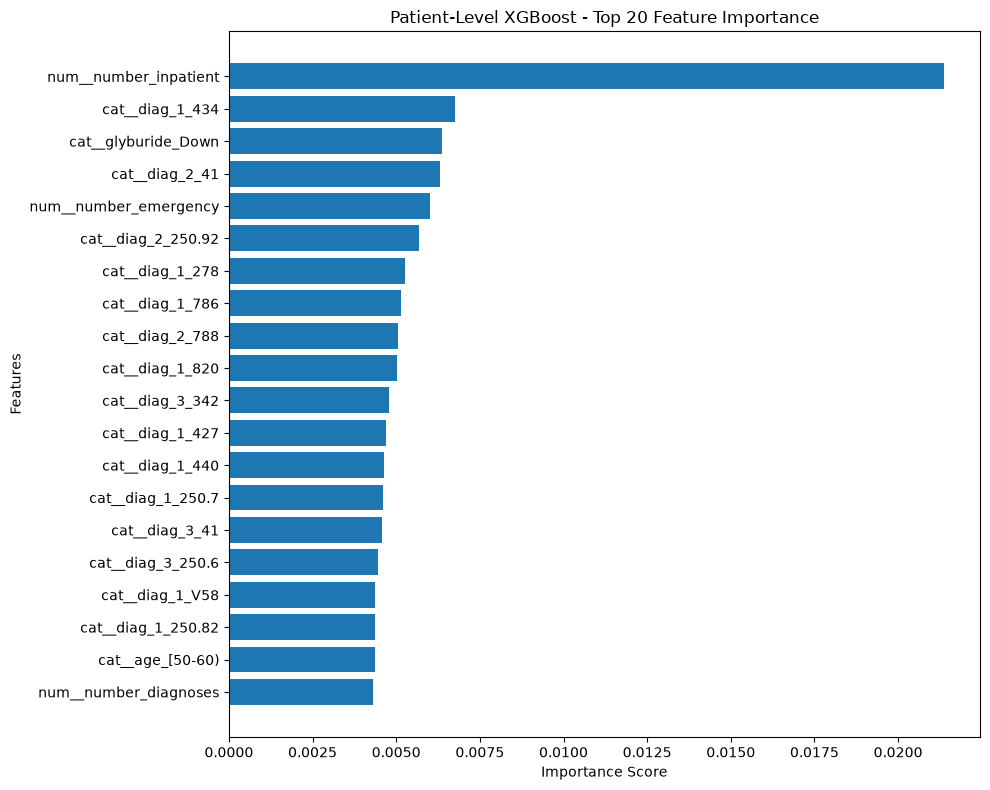

Patient-level feature importance graph saved successfully!


In [143]:
plt.figure(figsize=(10, 8))

top_group_features = xgb_group_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.barh(
    top_group_features["Feature"],
    top_group_features["Importance"]
)

plt.title("Patient-Level XGBoost - Top 20 Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()

plt.savefig(
    "../images/patient_level_xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Patient-level feature importance graph saved successfully!")

In [144]:
import joblib

joblib.dump(
    preprocessor,
    "../reports/patient_level_preprocessor.pkl"
)

joblib.dump(
    logistic_group_model,
    "../reports/patient_level_logistic_regression.pkl"
)

joblib.dump(
    rf_group_model,
    "../reports/patient_level_random_forest.pkl"
)

joblib.dump(
    xgb_group_model,
    "../reports/patient_level_xgboost.pkl"
)

print("All patient-level models saved successfully!")

All patient-level models saved successfully!


In [145]:
import joblib

loaded_preprocessor = joblib.load(
    "../reports/patient_level_preprocessor.pkl"
)

loaded_logistic = joblib.load(
    "../reports/patient_level_logistic_regression.pkl"
)

loaded_random_forest = joblib.load(
    "../reports/patient_level_random_forest.pkl"
)

loaded_xgboost = joblib.load(
    "../reports/patient_level_xgboost.pkl"
)

print("All saved models loaded successfully!")

All saved models loaded successfully!


In [146]:
sample_data = X_test_group.iloc[:5]

sample_processed = loaded_preprocessor.transform(sample_data)

sample_predictions = loaded_xgboost.predict(sample_processed)

sample_probabilities = loaded_xgboost.predict_proba(sample_processed)[:, 1]

sample_results = pd.DataFrame({
    "Actual": y_test_group.iloc[:5].values,
    "Predicted": sample_predictions,
    "Readmission_Risk": sample_probabilities
})

sample_results

,Actual,Predicted,Readmission_Risk
0,0,1,0.562755
1,0,0,0.392157
2,0,1,0.524530
3,0,1,0.532200
4,0,0,0.461277


In [147]:
sample_results["Actual_Label"] = sample_results["Actual"].map({
    0: "No Readmission",
    1: "Readmission Within 30 Days"
})

sample_results["Predicted_Label"] = sample_results["Predicted"].map({
    0: "No Readmission",
    1: "Readmission Within 30 Days"
})

sample_results["Readmission_Risk"] = (
    sample_results["Readmission_Risk"] * 100
).round(2)

sample_results

,Actual,Predicted,Readmission_Risk,Actual_Label,Predicted_Label
0,0,1,56.279999,No Readmission,Readmission Within 30 Days
1,0,0,39.220001,No Readmission,No Readmission
2,0,1,52.450001,No Readmission,Readmission Within 30 Days
3,0,1,53.220001,No Readmission,Readmission Within 30 Days
4,0,0,46.130001,No Readmission,No Readmission


In [148]:
sample_results["Readmission_Risk"] = (
    sample_results["Readmission_Risk"].round(2)
)

sample_results = sample_results[
    [
        "Actual_Label",
        "Predicted_Label",
        "Readmission_Risk"
    ]
]

sample_results

,Actual_Label,Predicted_Label,Readmission_Risk
0,No Readmission,Readmission Within 30 Days,56.279999
1,No Readmission,No Readmission,39.220001
2,No Readmission,Readmission Within 30 Days,52.450001
3,No Readmission,Readmission Within 30 Days,53.220001
4,No Readmission,No Readmission,46.130001


In [149]:
sample_results["Readmission_Risk"] = (
    sample_results["Readmission_Risk"]
    .map(lambda x: f"{x:.2f}%")
)

sample_results

,Actual_Label,Predicted_Label,Readmission_Risk
0,No Readmission,Readmission Within 30 Days,56.28%
1,No Readmission,No Readmission,39.22%
2,No Readmission,Readmission Within 30 Days,52.45%
3,No Readmission,Readmission Within 30 Days,53.22%
4,No Readmission,No Readmission,46.13%


In [150]:
print("Total Features:", len(X.columns))

for i, column in enumerate(X.columns, 1):
    print(i, column, "-", X[column].dtype)

Total Features: 45
1 race - str
2 gender - str
3 age - str
4 time_in_hospital - int64
5 payer_code - str
6 medical_specialty - str
7 num_lab_procedures - int64
8 num_procedures - int64
9 num_medications - int64
10 number_outpatient - int64
11 number_emergency - int64
12 number_inpatient - int64
13 diag_1 - str
14 diag_2 - str
15 diag_3 - str
16 number_diagnoses - int64
17 max_glu_serum - str
18 A1Cresult - str
19 metformin - str
20 repaglinide - str
21 nateglinide - str
22 chlorpropamide - str
23 glimepiride - str
24 acetohexamide - str
25 glipizide - str
26 glyburide - str
27 tolbutamide - str
28 pioglitazone - str
29 rosiglitazone - str
30 acarbose - str
31 miglitol - str
32 troglitazone - str
33 tolazamide - str
34 examide - str
35 citoglipton - str
36 insulin - str
37 glyburide-metformin - str
38 glipizide-metformin - str
39 glimepiride-pioglitazone - str
40 metformin-rosiglitazone - str
41 metformin-pioglitazone - str
42 change - str
43 diabetesMed - str
44 admission_type - str
45

In [151]:
for i, column in enumerate(X.columns, 1):
    if 20 <= i <= 42:
        print(f"{i}. {column}")

20. repaglinide
21. nateglinide
22. chlorpropamide
23. glimepiride
24. acetohexamide
25. glipizide
26. glyburide
27. tolbutamide
28. pioglitazone
29. rosiglitazone
30. acarbose
31. miglitol
32. troglitazone
33. tolazamide
34. examide
35. citoglipton
36. insulin
37. glyburide-metformin
38. glipizide-metformin
39. glimepiride-pioglitazone
40. metformin-rosiglitazone
41. metformin-pioglitazone
42. change
